In [1]:
import pandas as pd
import numpy as np

In [2]:
#Read data (the file sits next to this notebook)
attrition = pd.read_excel("IBM Employee Attrition.xlsx")

In [3]:
#view the top 5 rows of the dataset
attrition.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
#Statistical summary of the data set
attrition.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [5]:
# Summary of the data frame
attrition.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [6]:
#Check for missing values in the data
attrition.isnull().any()

Age                         False
Attrition                   False
BusinessTravel              False
DailyRate                   False
Department                  False
DistanceFromHome            False
Education                   False
EducationField              False
EmployeeCount               False
EmployeeNumber              False
EnvironmentSatisfaction     False
Gender                      False
HourlyRate                  False
JobInvolvement              False
JobLevel                    False
JobRole                     False
JobSatisfaction             False
MaritalStatus               False
MonthlyIncome               False
MonthlyRate                 False
NumCompaniesWorked          False
Over18                      False
OverTime                    False
PercentSalaryHike           False
PerformanceRating           False
RelationshipSatisfaction    False
StandardHours               False
StockOptionLevel            False
TotalWorkingYears           False
TrainingTimesL

In [7]:
#Dummify the Attrition column
attrition["Attrition"] = attrition["Attrition"].map({"Yes": 1, "No": 0}).astype("int64")
attrition.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [8]:
# View the categorical columns and store in categorical
categorical = attrition.select_dtypes(include = 'object')
print(categorical.columns)

Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'Over18', 'OverTime'],
      dtype='str')


/tmp/ipykernel_418/2924132364.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = attrition.select_dtypes(include = 'object')


In [9]:
#View the unique values in the categorical columns
for col in categorical:
    print(col, ':', categorical[col].unique())

BusinessTravel : <StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str
Department : <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str
EducationField : <StringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str
Gender : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
JobRole : <StringArray>
[          'Sales Executive',        'Research Scientist',
     'Laboratory Technician',    'Manufacturing Director',
 'Healthcare Representative',                   'Manager',
      'Sales Representative',         'Research Director',
           'Human Resources']
Length: 9, dtype: str
MaritalStatus : <StringArray>
['Single', 'Married', 'Divorced']
Length: 3, dtype: str
Over18 : <StringArray>
['Y']
Length: 1, dtype: str
OverTime : <StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [10]:
#View the numerical columns and store as numerical
numerical = attrition.select_dtypes(include=['int64'])
print((numerical.columns))

Index(['Age', 'Attrition', 'DailyRate', 'DistanceFromHome', 'Education',
       'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction',
       'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StandardHours', 'StockOptionLevel', 'TotalWorkingYears',
       'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany',
       'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')


In [11]:
#View the unique values in the categorical columns
for col in numerical:
    print(col, ':', numerical[col].unique())

Age : [41 49 37 33 27 32 59 30 38 36 35 29 31 34 28 22 53 24 21 42 44 46 39 43
 50 26 48 55 45 56 23 51 40 54 58 20 25 19 57 52 47 18 60]
Attrition : [1 0]
DailyRate : [1102  279 1373 1392  591 1005 1324 1358  216 1299  809  153  670 1346
  103 1389  334 1123 1219  371  673 1218  419  391  699 1282 1125  691
  477  705  924 1459  125  895  813 1273  869  890  852 1141  464 1240
 1357  994  721 1360 1065  408 1211 1229  626 1434 1488 1097 1443  515
  853 1142  655 1115  427  653  989 1435 1223  836 1195 1339  664  318
 1225 1328 1082  548  132  746  776  193  397  945 1214  111  573 1153
 1400  541  432  288  669  530  632 1334  638 1093 1217 1353  120  682
  489  807  827  871  665 1040 1420  240 1280  534 1456  658  142 1127
 1031 1189 1354 1467  922  394 1312  750  441  684  249  841  147  528
  594  470  957  542  802 1355 1150 1329  959 1033 1316  364  438  689
  201 1427  857  933 1181 1395  662 1436  194  967 1496 1169 1145  630
  303 1256  440 1450 1452  465  702 1157  602 1480 

In [12]:
continious = ['TotalWorkingYears', 'MonthlyIncome' ,'YearsAtCompany' ,'DistanceFromHome' ,'YearsWithCurrManager' ,'YearsSinceLastPromotion' ,'PercentSalaryHike' ,'TrainingTimesLastYear' ,'Age' ,'DailyRate' ,'HourlyRate' ,'MonthlyRate']
print(continious)

['TotalWorkingYears', 'MonthlyIncome', 'YearsAtCompany', 'DistanceFromHome', 'YearsWithCurrManager', 'YearsSinceLastPromotion', 'PercentSalaryHike', 'TrainingTimesLastYear', 'Age', 'DailyRate', 'HourlyRate', 'MonthlyRate']


In [13]:
#Drop irrelivant columns
attrition.drop(columns=["Over18", "EmployeeCount", "StandardHours", "EmployeeNumber"], inplace=True)


<Figure size 1280x960 with 0 Axes>

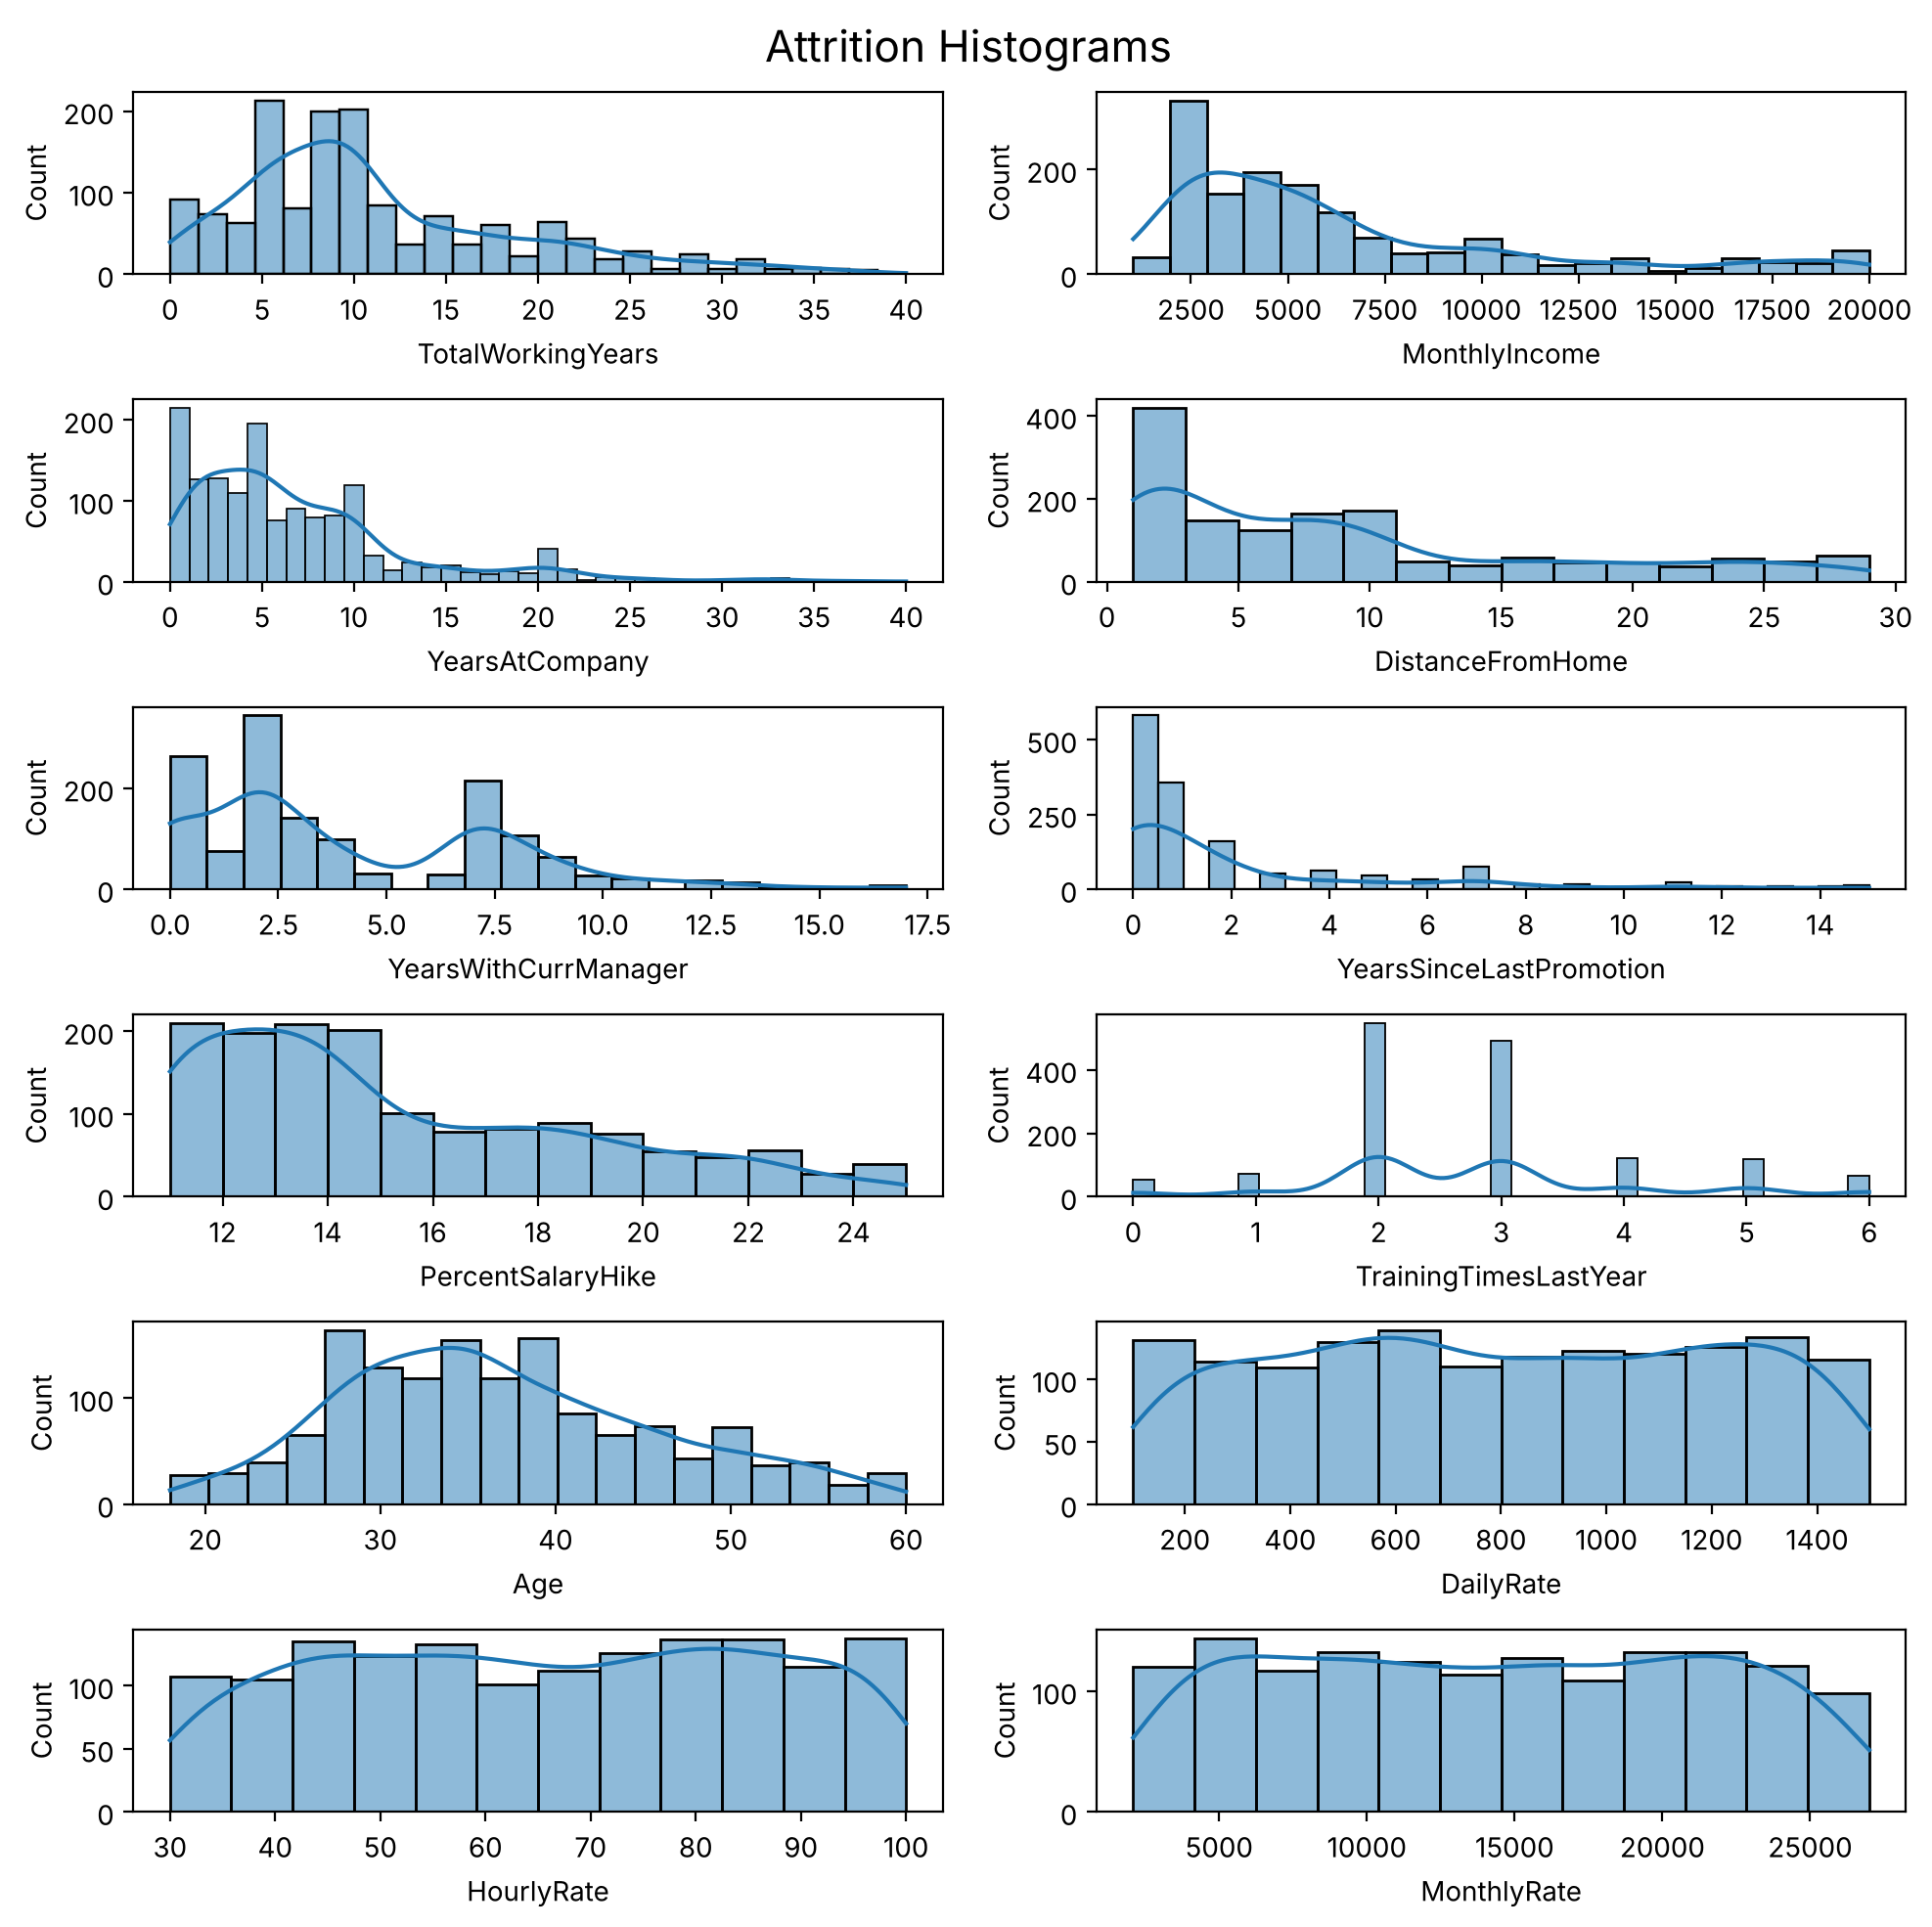

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.tight_layout()
fig, axs = plt.subplots(6, 2, figsize=(10, 10))
sns.histplot(attrition['TotalWorkingYears'], kde=True, ax=axs[0, 0])
sns.histplot(attrition['MonthlyIncome'], kde=True, ax=axs[0, 1])
sns.histplot(attrition['YearsAtCompany'], kde=True, ax=axs[1, 0])
sns.histplot(attrition['DistanceFromHome'], kde=True, ax=axs[1, 1])
sns.histplot(attrition['YearsWithCurrManager'], kde=True, ax=axs[2, 0])
sns.histplot(attrition['YearsSinceLastPromotion'], kde=True, ax=axs[2, 1])
sns.histplot(attrition['PercentSalaryHike'], kde=True, ax=axs[3, 0])
sns.histplot(attrition['TrainingTimesLastYear'], kde=True, ax=axs[3, 1])
sns.histplot(attrition['Age'], kde=True, ax=axs[4, 0])
sns.histplot(attrition['DailyRate'], kde=True, ax=axs[4, 1])
sns.histplot(attrition['HourlyRate'], kde=True, ax=axs[5, 0])
sns.histplot(attrition['MonthlyRate'], kde=True, ax=axs[5, 1])

fig.suptitle('Attrition Histograms', fontsize=16)
plt.tight_layout()
plt.show()


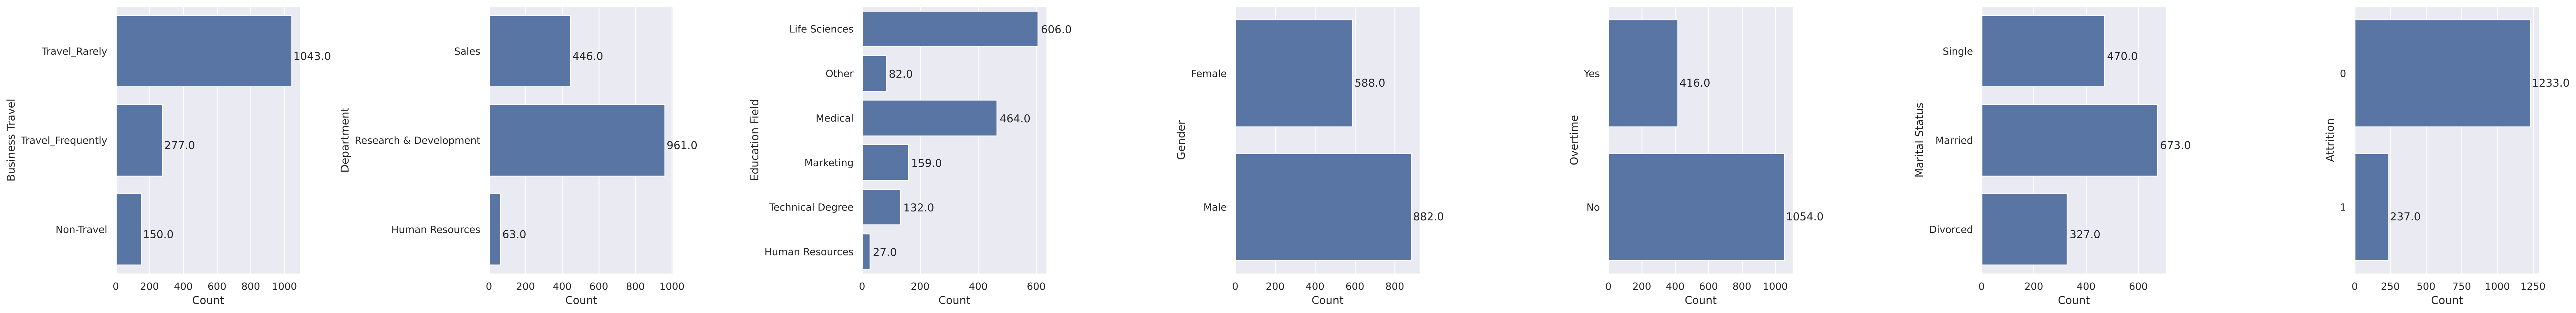

In [15]:
sns.set(style="darkgrid")
fig, axs = plt.subplots(1, 7, figsize=(40, 5))

sns.countplot(data=attrition, y='BusinessTravel', ax=axs[0])
axs[0].set_ylabel('Business Travel')
axs[0].set_xlabel('Count')
axs[0].tick_params(axis='y', rotation=0)
for p in axs[0].patches:
    axs[0].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

sns.countplot(data=attrition, y='Department', ax=axs[1])
axs[1].set_ylabel('Department')
axs[1].set_xlabel('Count')
axs[1].tick_params(axis='y', rotation=0)
for p in axs[1].patches:
    axs[1].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

sns.countplot(data=attrition, y='EducationField', ax=axs[2])
axs[2].set_ylabel('Education Field')
axs[2].set_xlabel('Count')
axs[2].tick_params(axis='y', rotation=0)
for p in axs[2].patches:
    axs[2].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

sns.countplot(data=attrition, y='Gender', ax=axs[3])
axs[3].set_ylabel('Gender')
axs[3].set_xlabel('Count')
axs[3].tick_params(axis='y', rotation=0)
for p in axs[3].patches:
    axs[3].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

sns.countplot(data=attrition, y='OverTime', ax=axs[4])
axs[4].set_ylabel('Overtime')
axs[4].set_xlabel('Count')
axs[4].tick_params(axis='y', rotation=0)
for p in axs[4].patches:
    axs[4].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

sns.countplot(data=attrition, y='MaritalStatus', ax=axs[5])
axs[5].set_ylabel('Marital Status')
axs[5].set_xlabel('Count')
axs[5].tick_params(axis='y', rotation=0)
for p in axs[5].patches:
    axs[5].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

sns.countplot(data=attrition, y='Attrition', ax=axs[6])
axs[6].set_ylabel('Attrition')
axs[6].set_xlabel('Count')
axs[6].tick_params(axis='y', rotation=0)
for p in axs[6].patches:
    axs[6].annotate(format(p.get_width()), (p.get_width() + 10, p.get_y() + 0.5))

fig.tight_layout()
plt.show()


In [16]:
numerical_df = attrition.select_dtypes(include=['int64', 'float64'])
continuous_df = attrition[['Age', 'DailyRate', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate']]

merged_df = pd.concat([numerical_df, continuous_df], axis=1)


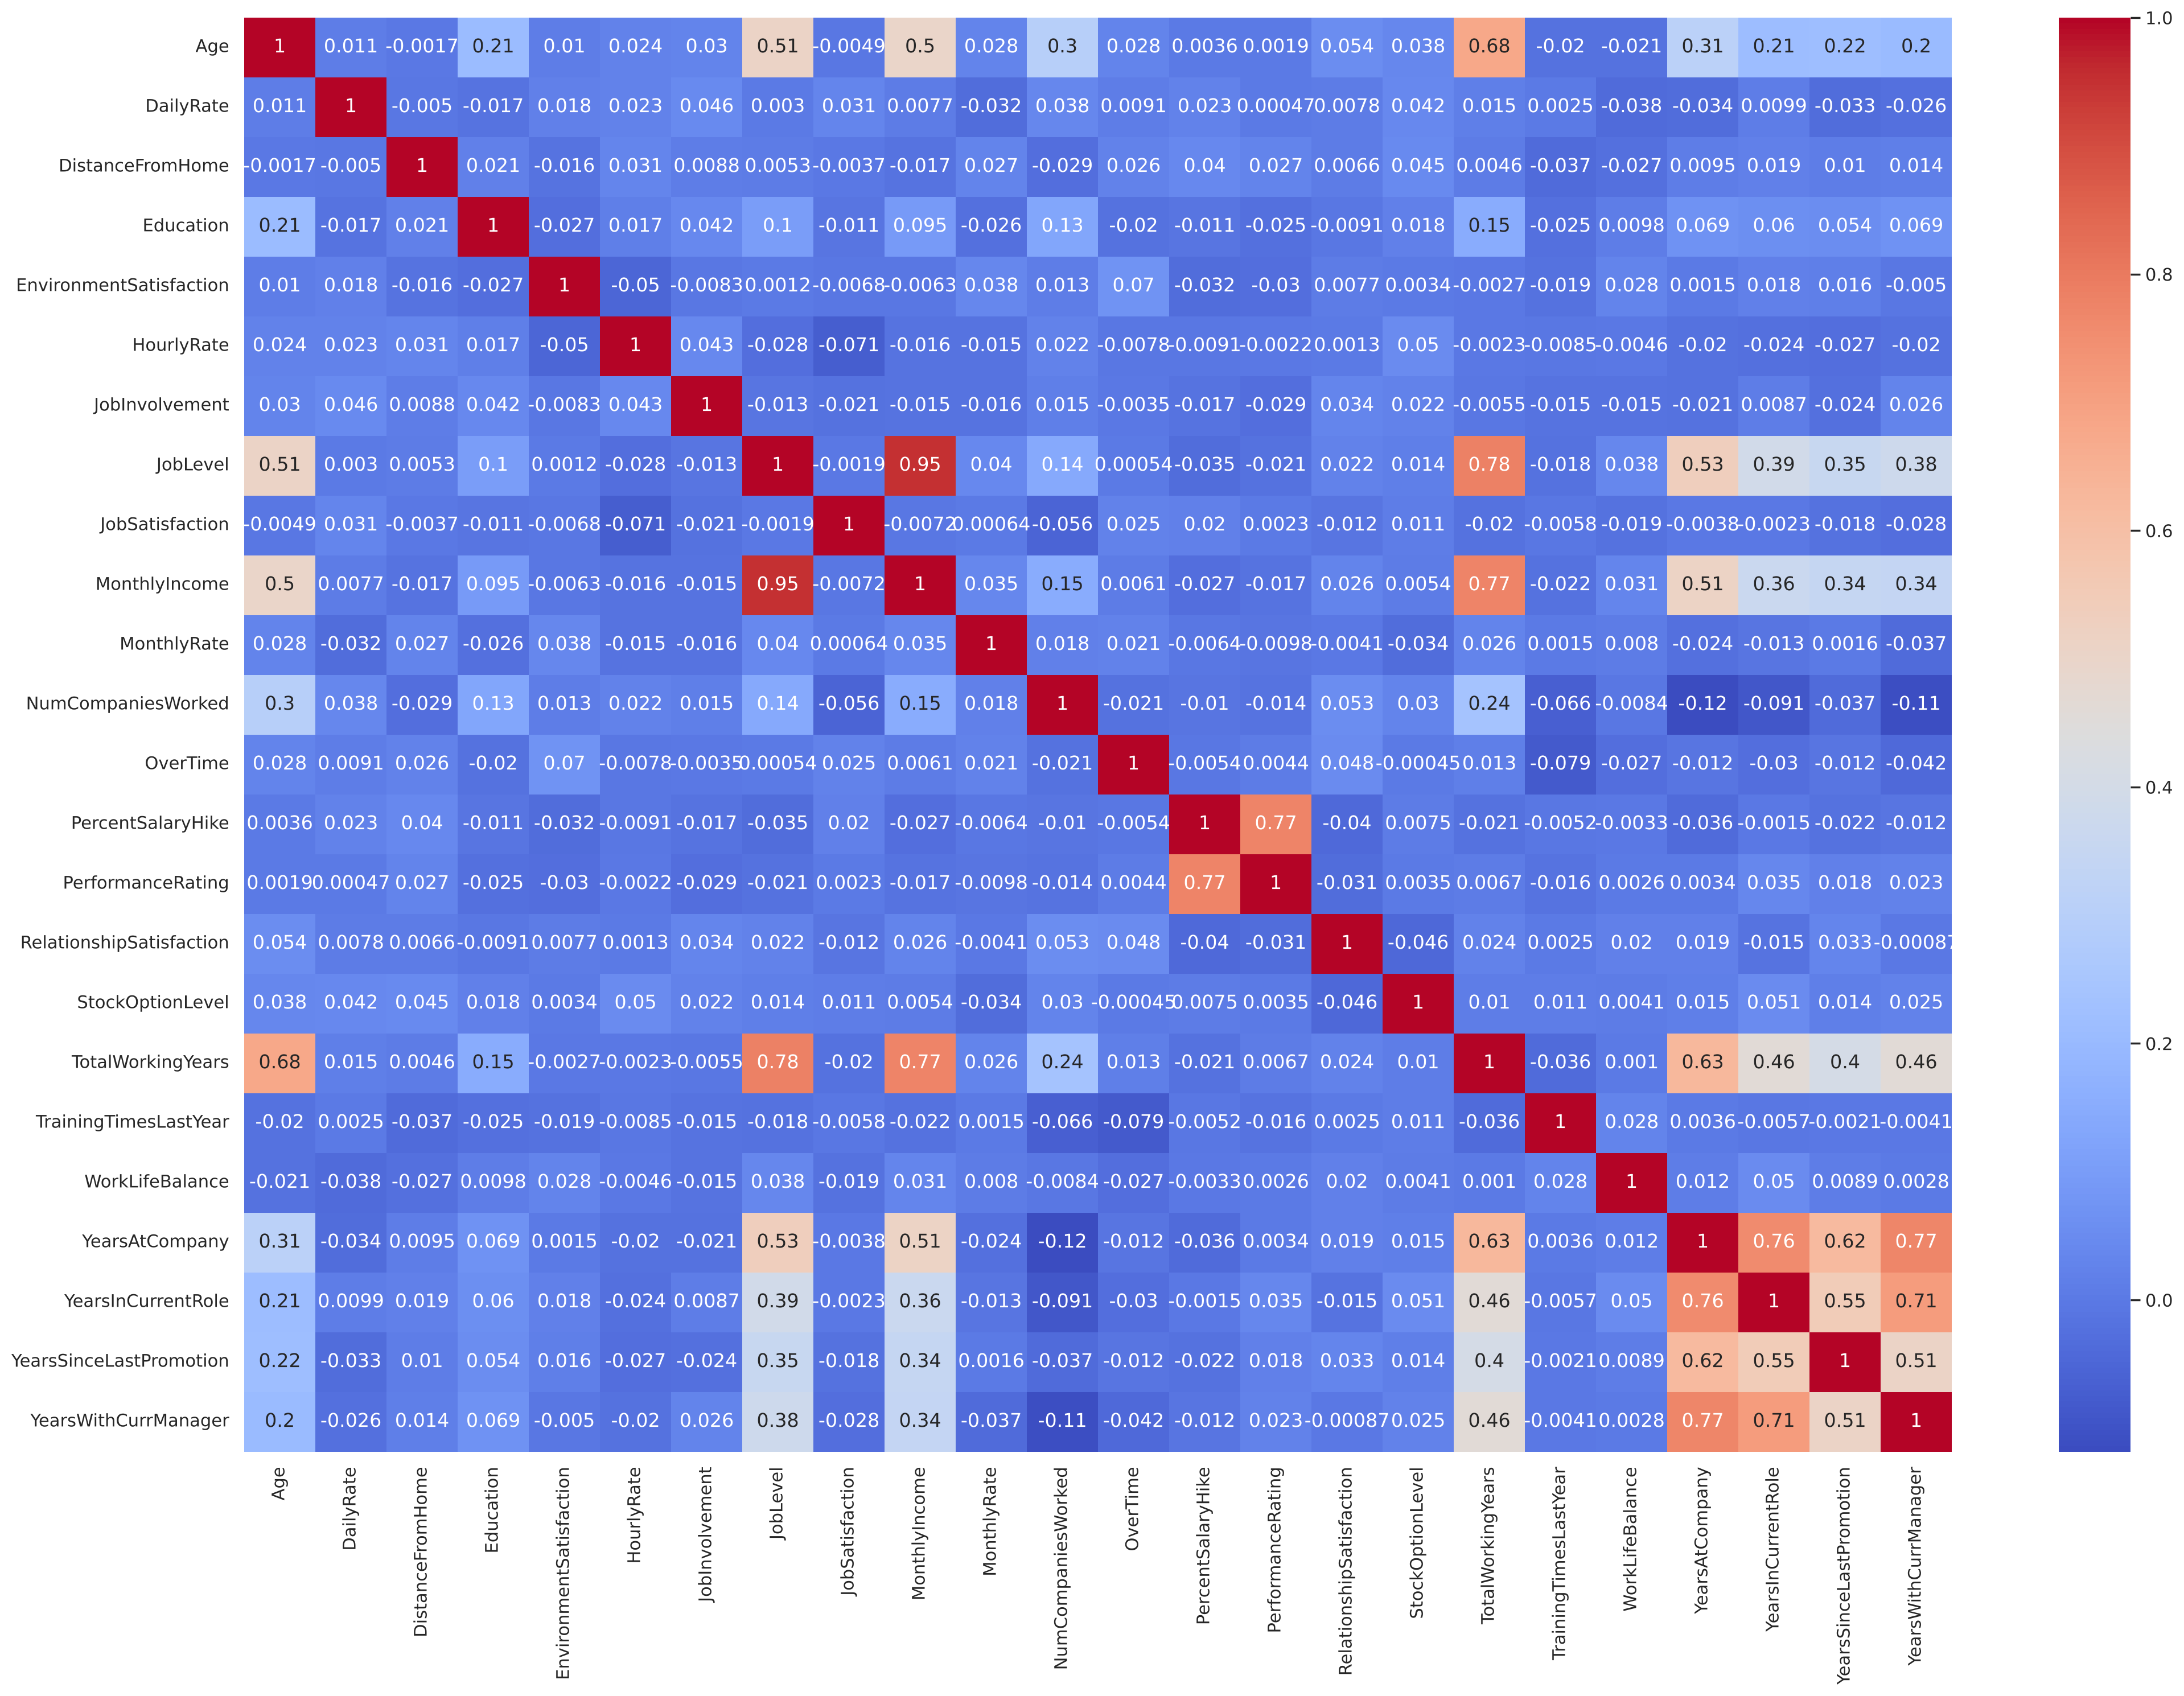

In [17]:
# Select only the numeric columns for the correlation matrix
numeric_cols = ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 
                'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 
                'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 
                'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 
                'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

# Create a correlation matrix using the .corr() method on the selected columns
corr_matrix = attrition[numeric_cols].assign(OverTime=attrition['OverTime'].map({'Yes': 1, 'No': 0})).corr()

# Set up the heatmap figure size and layout
plt.figure(figsize=(25, 20))
plt.subplots_adjust(left=0.15, bottom=0.25)

# Create the heatmap using the seaborn .heatmap() function
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

# Show the heatmap
plt.show()


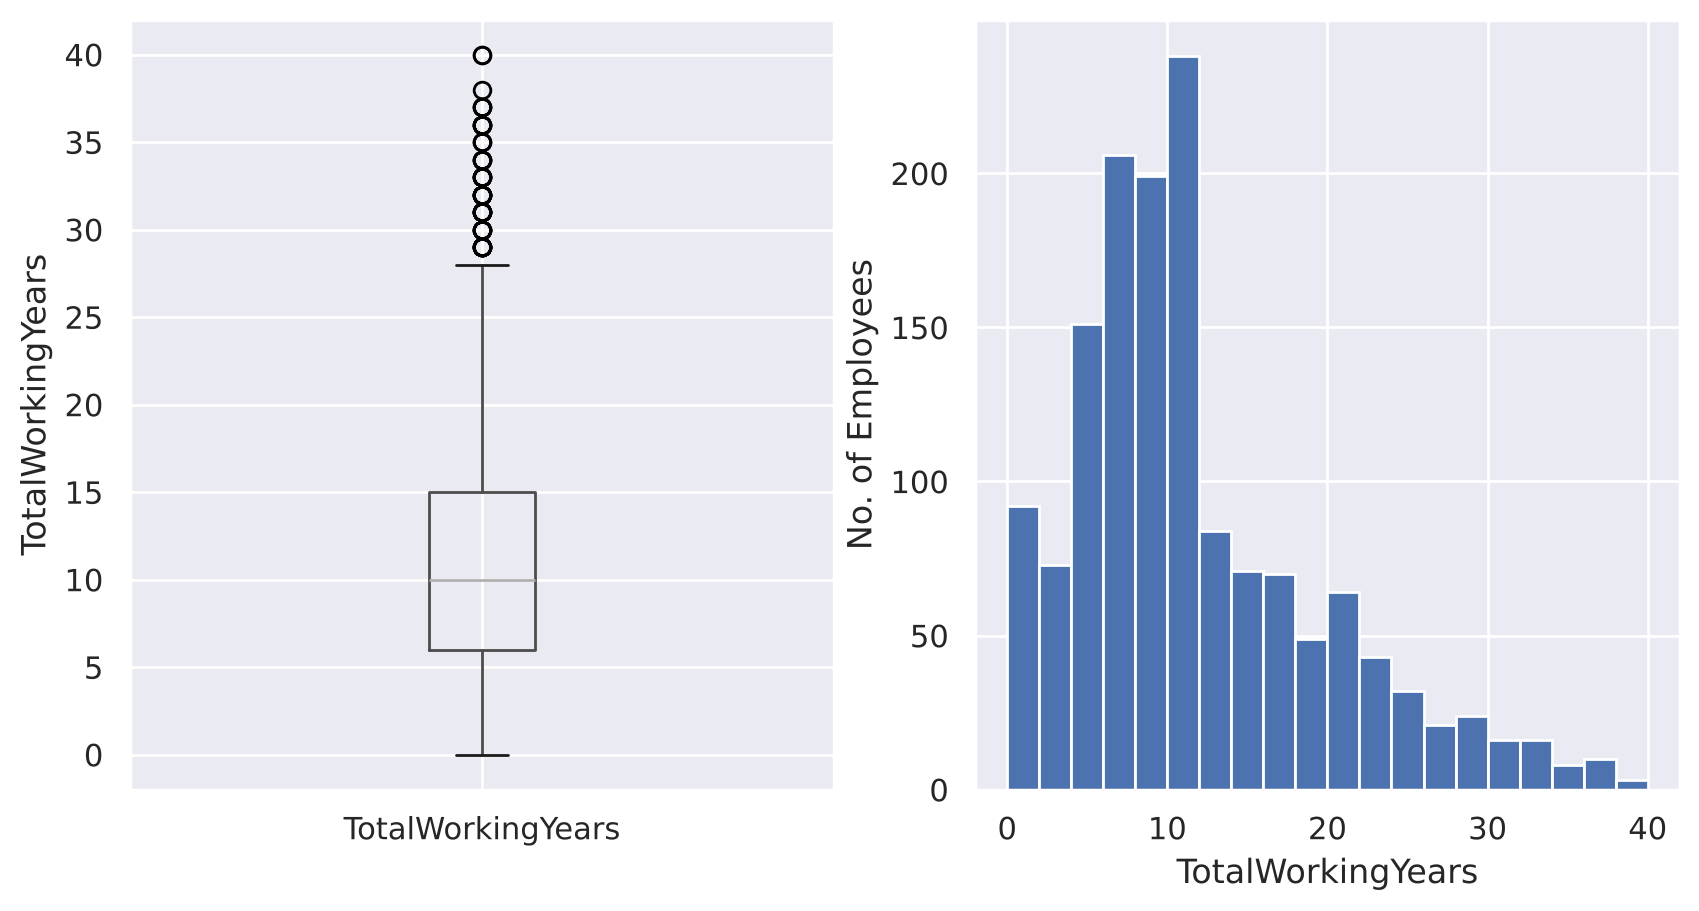

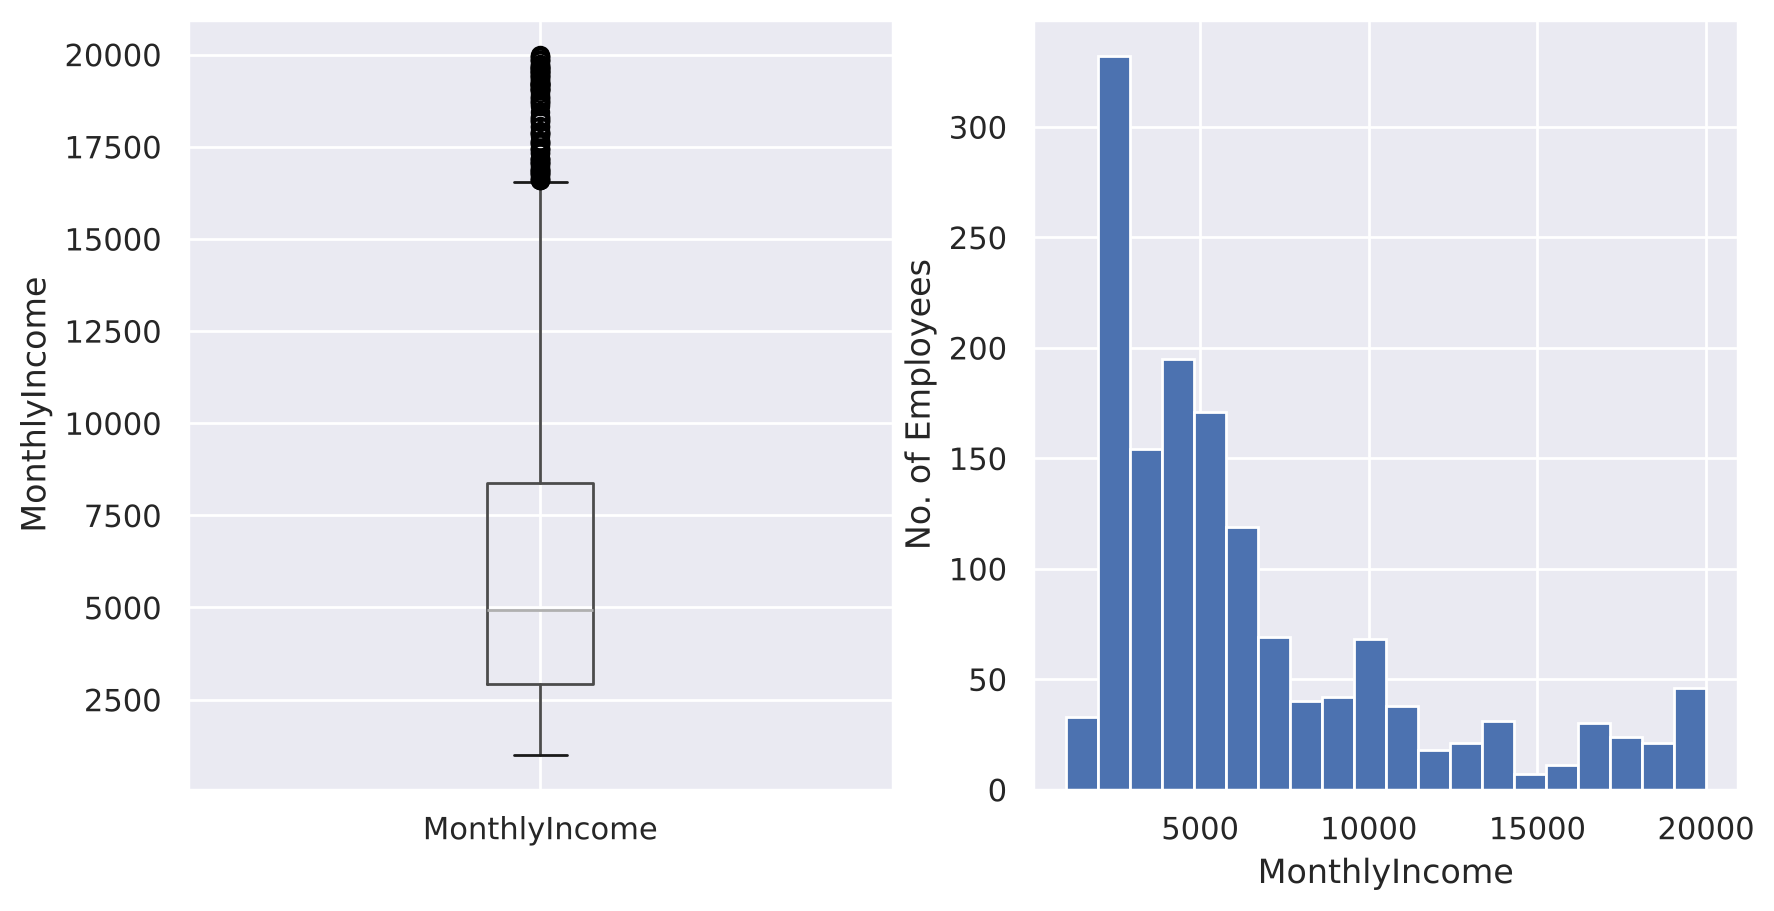

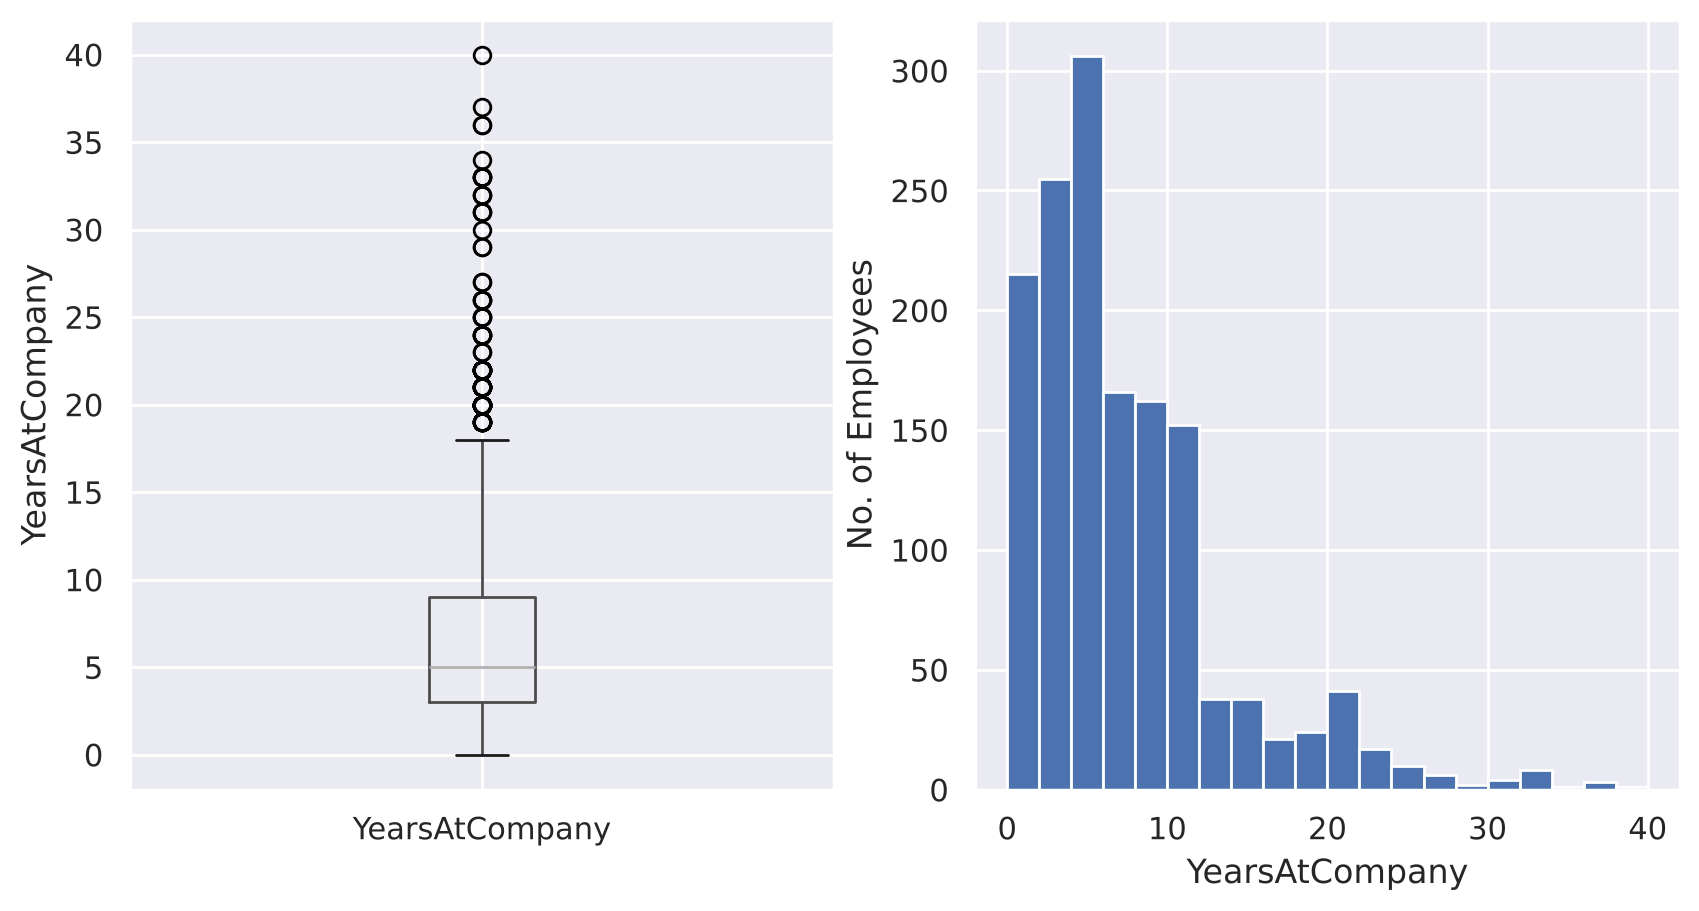

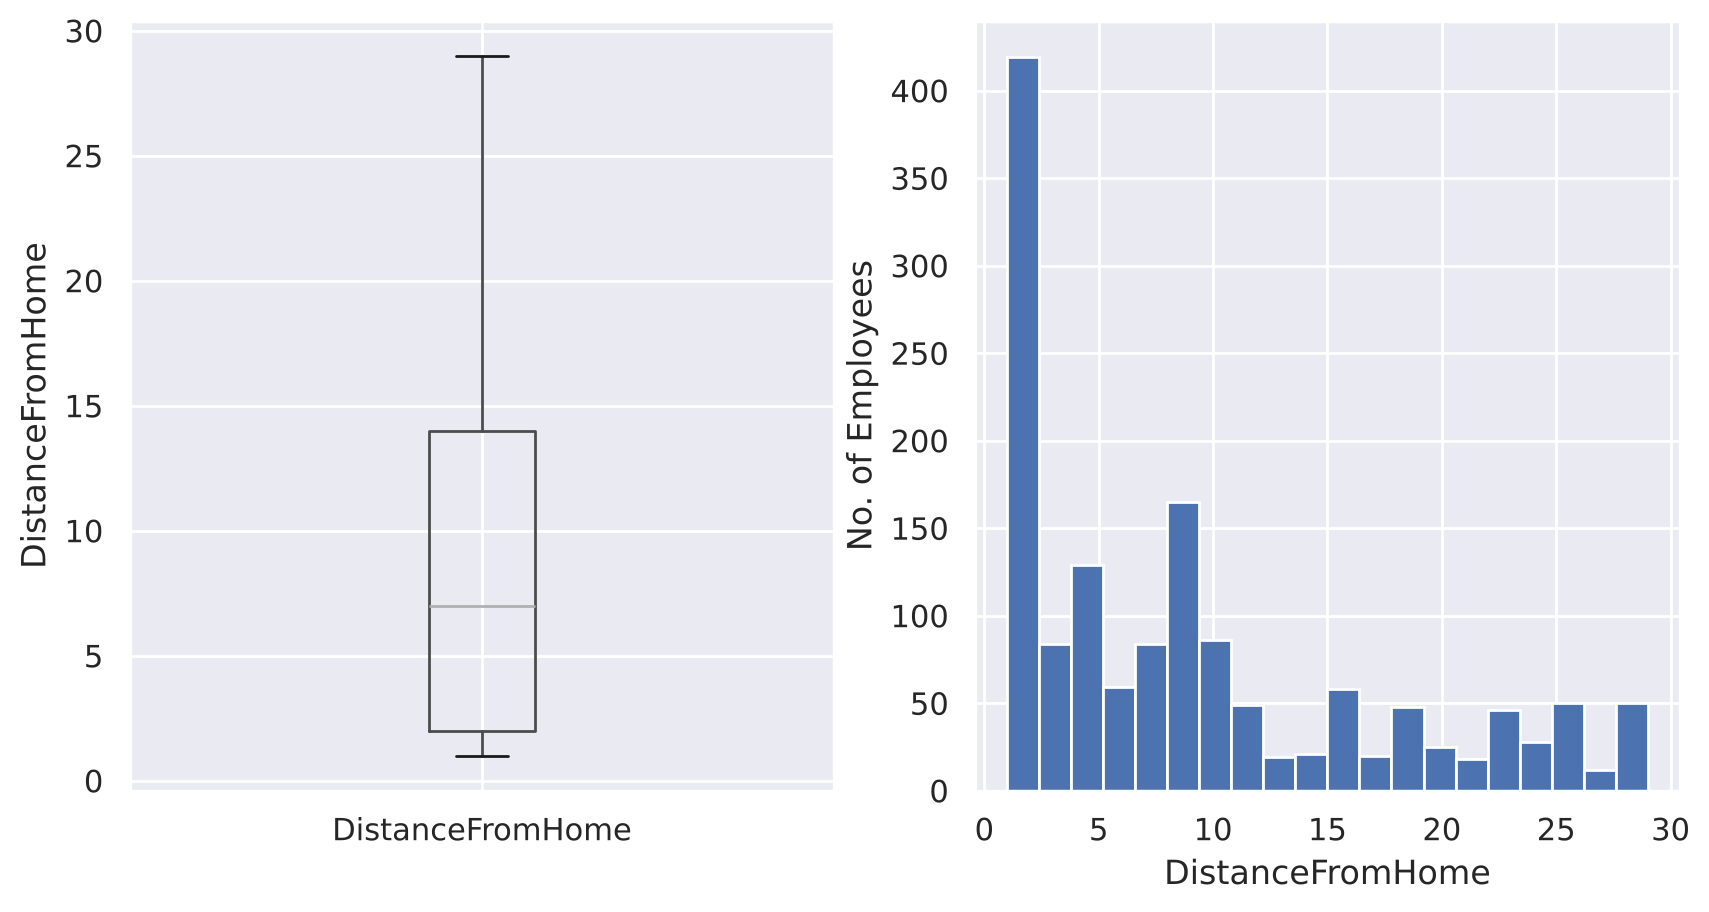

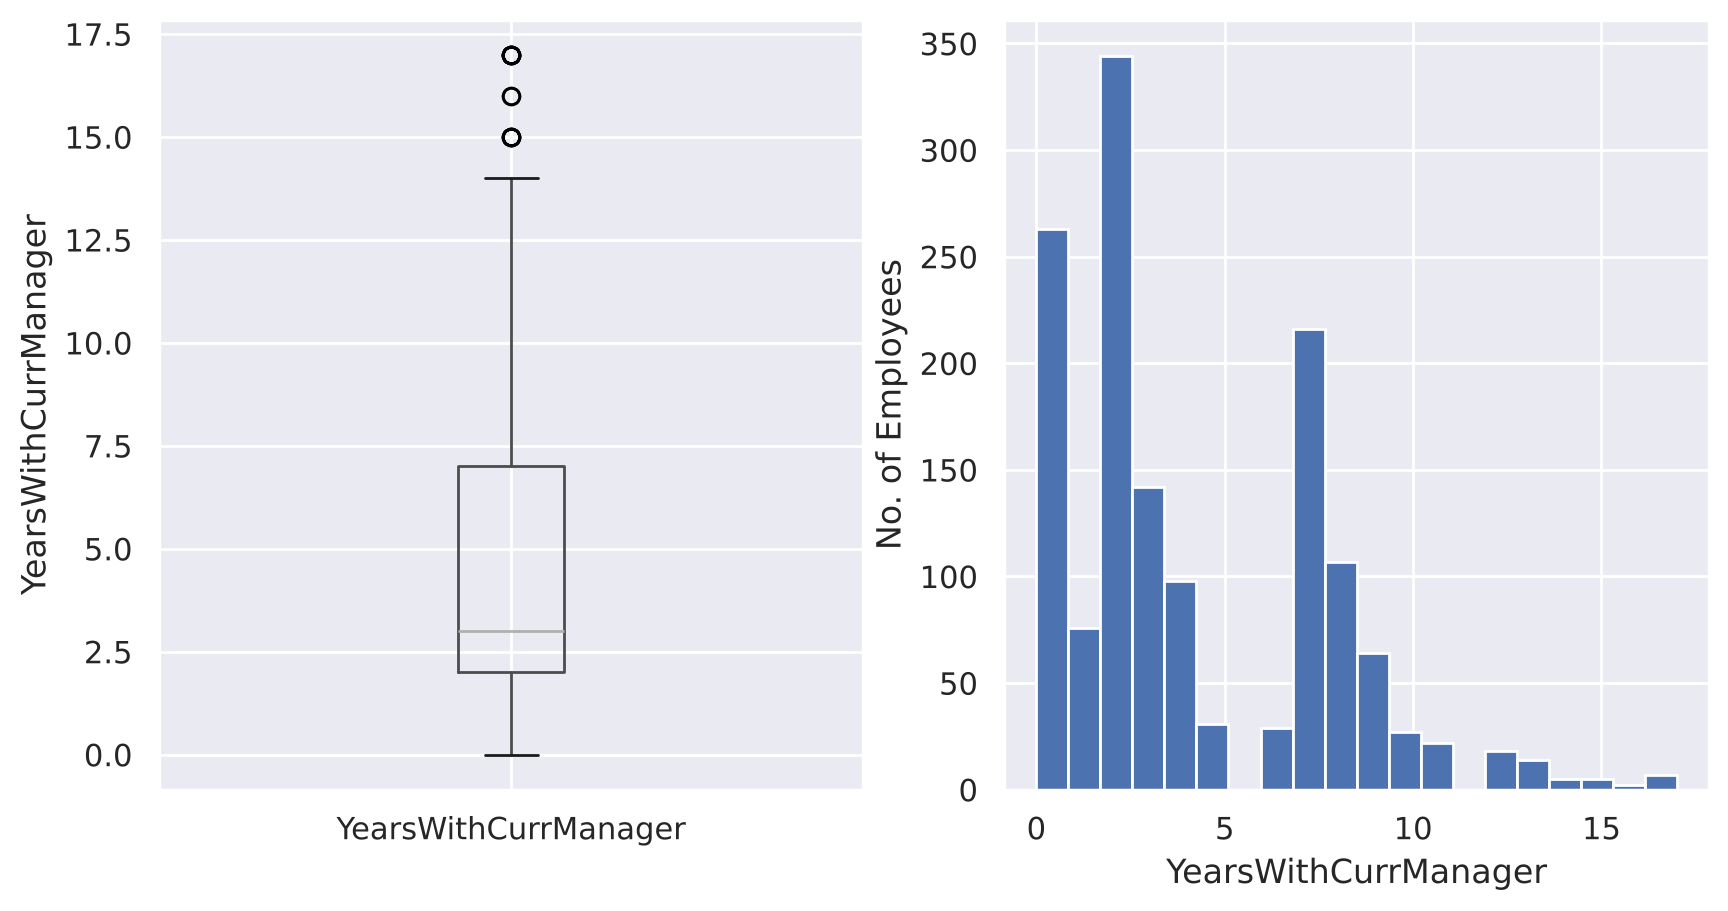

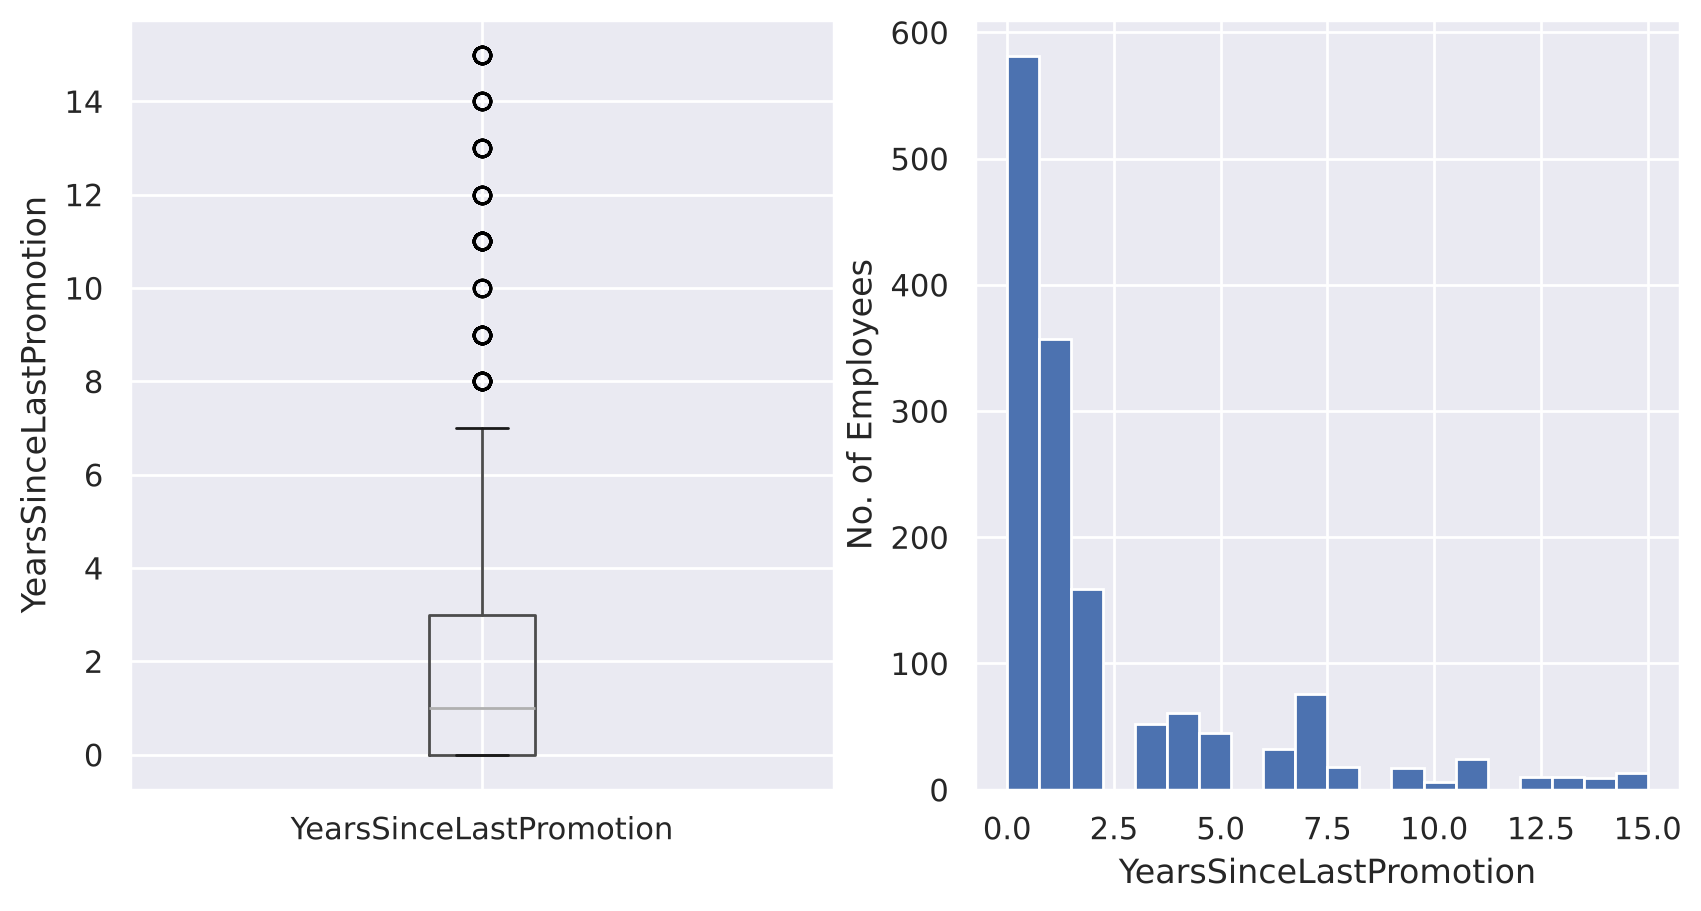

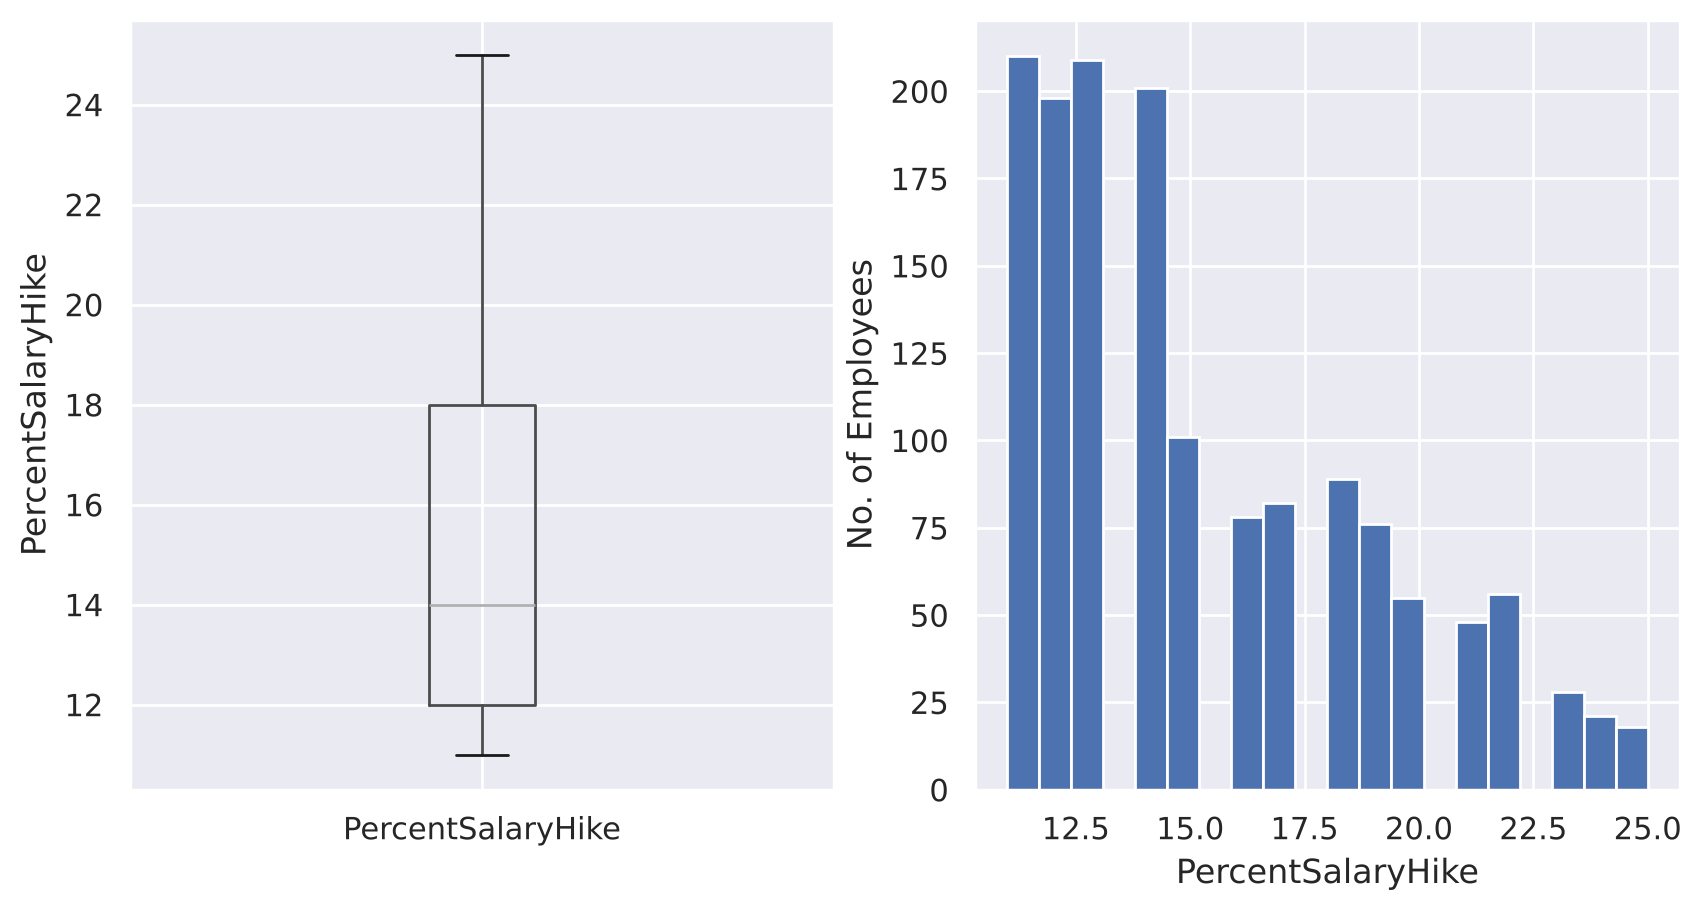

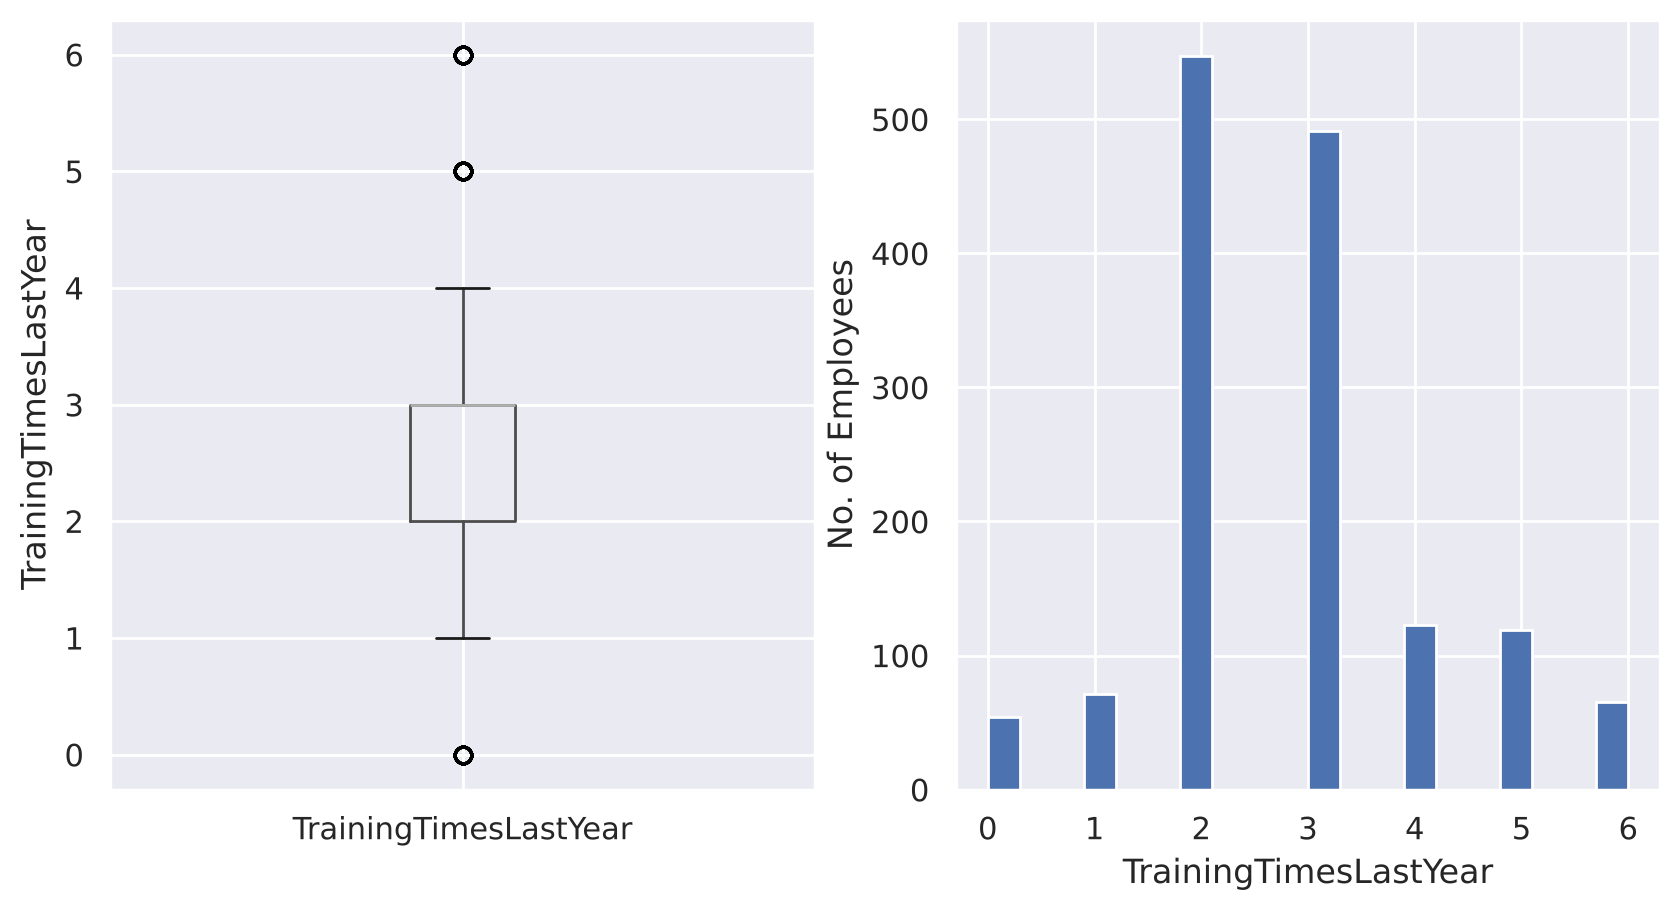

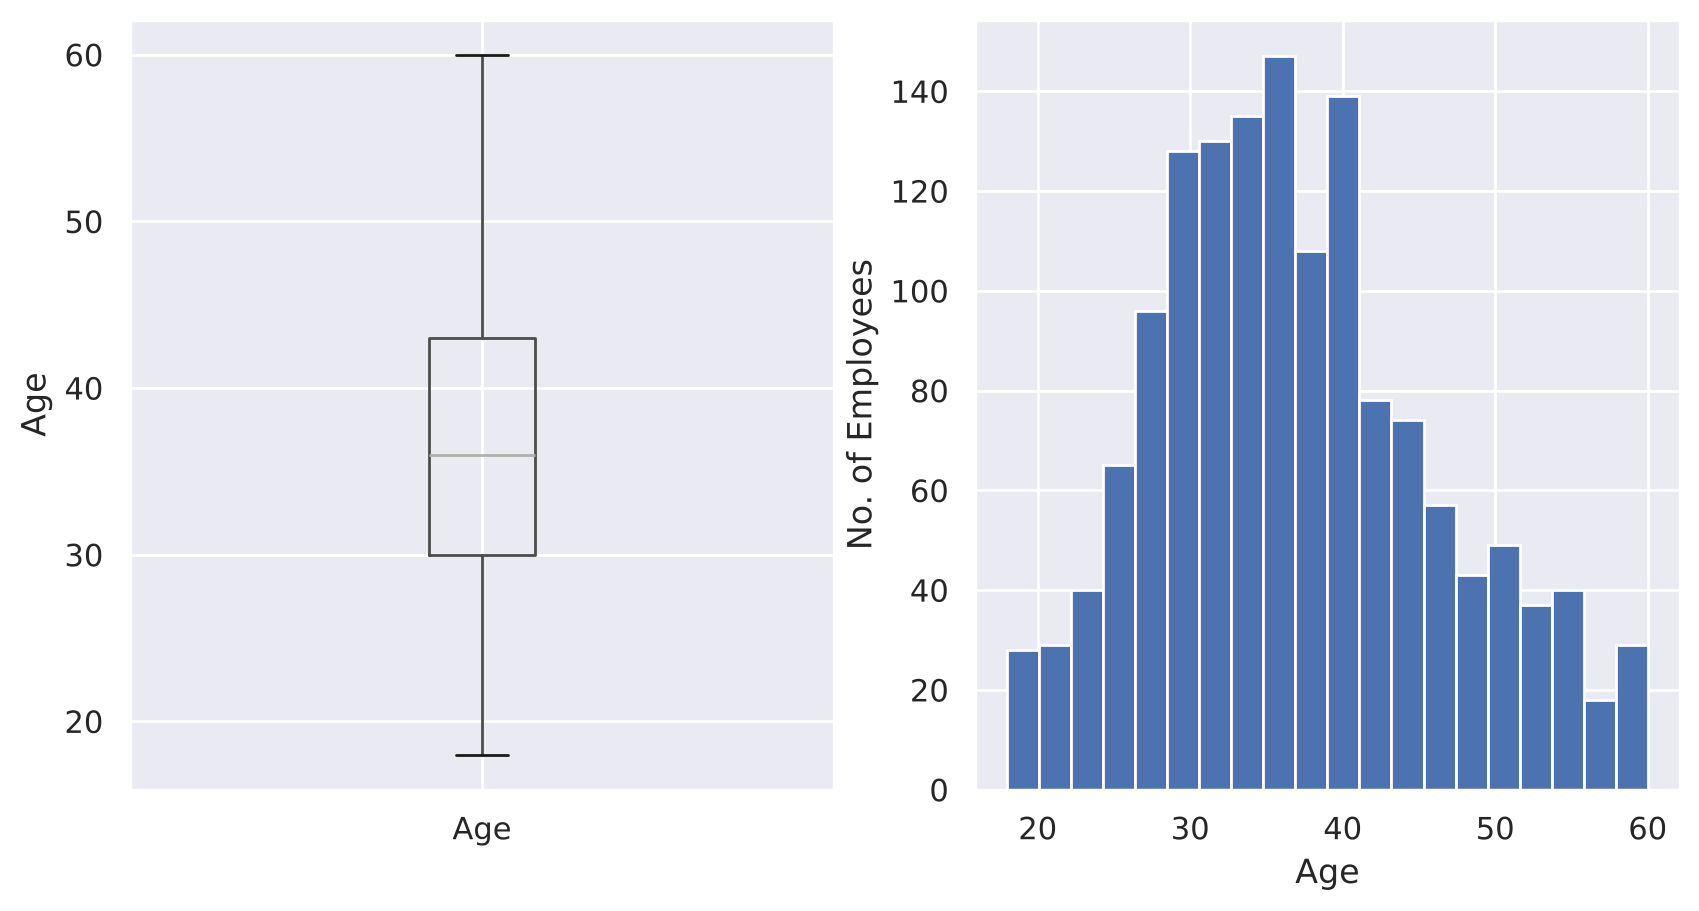

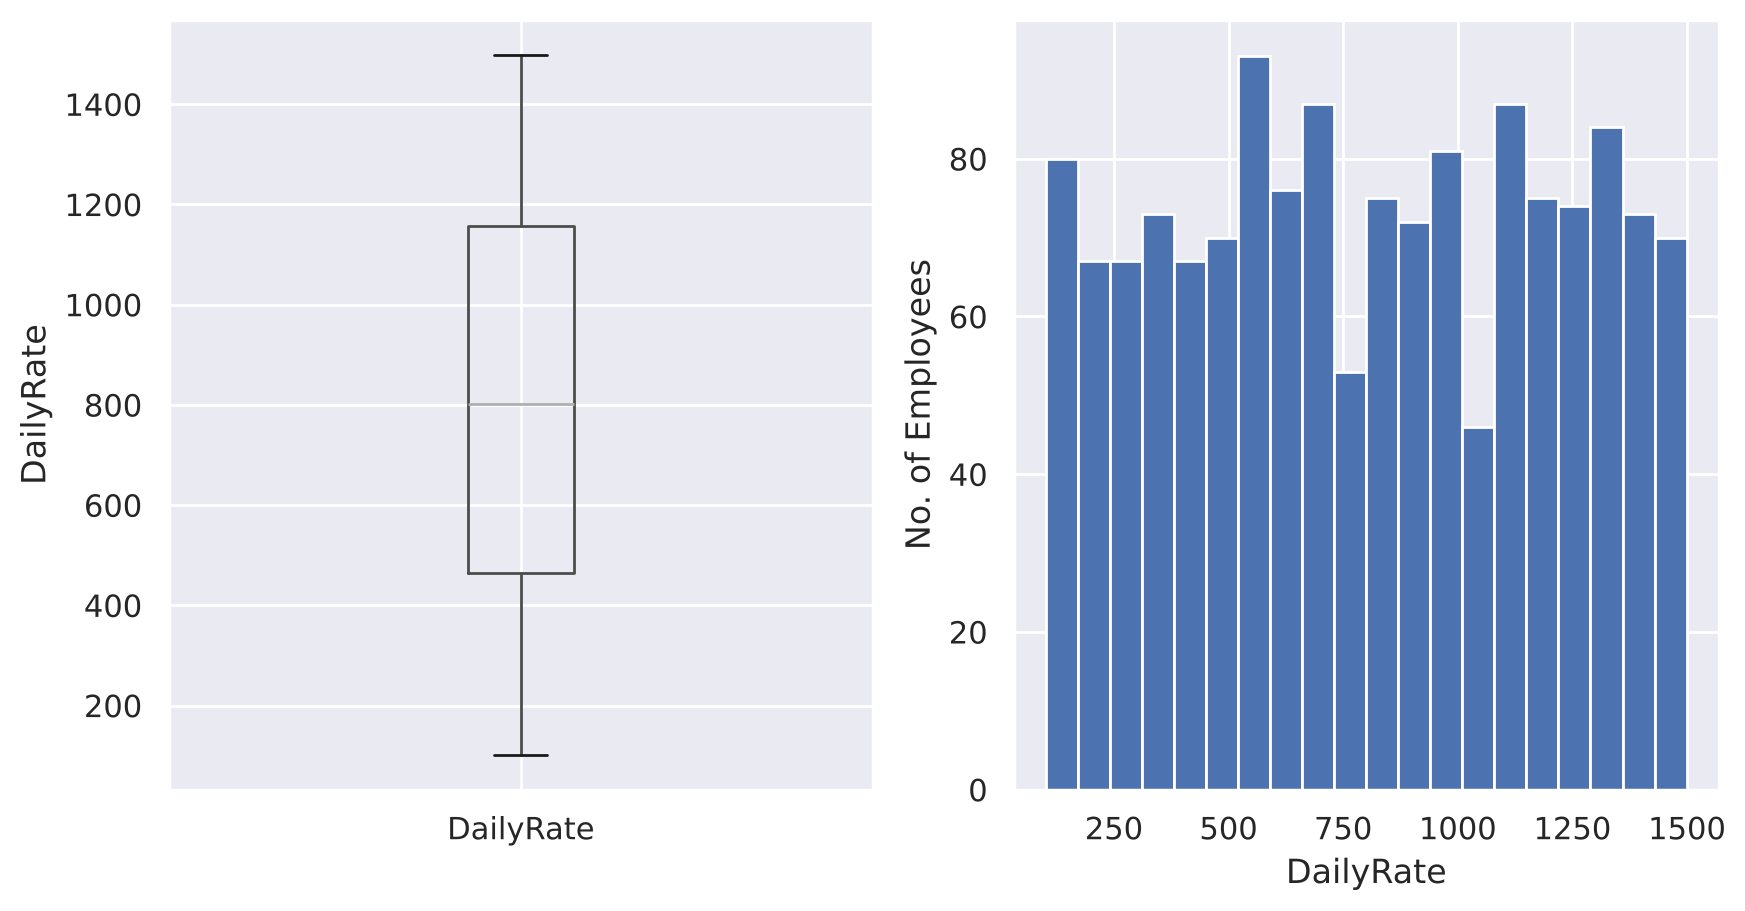

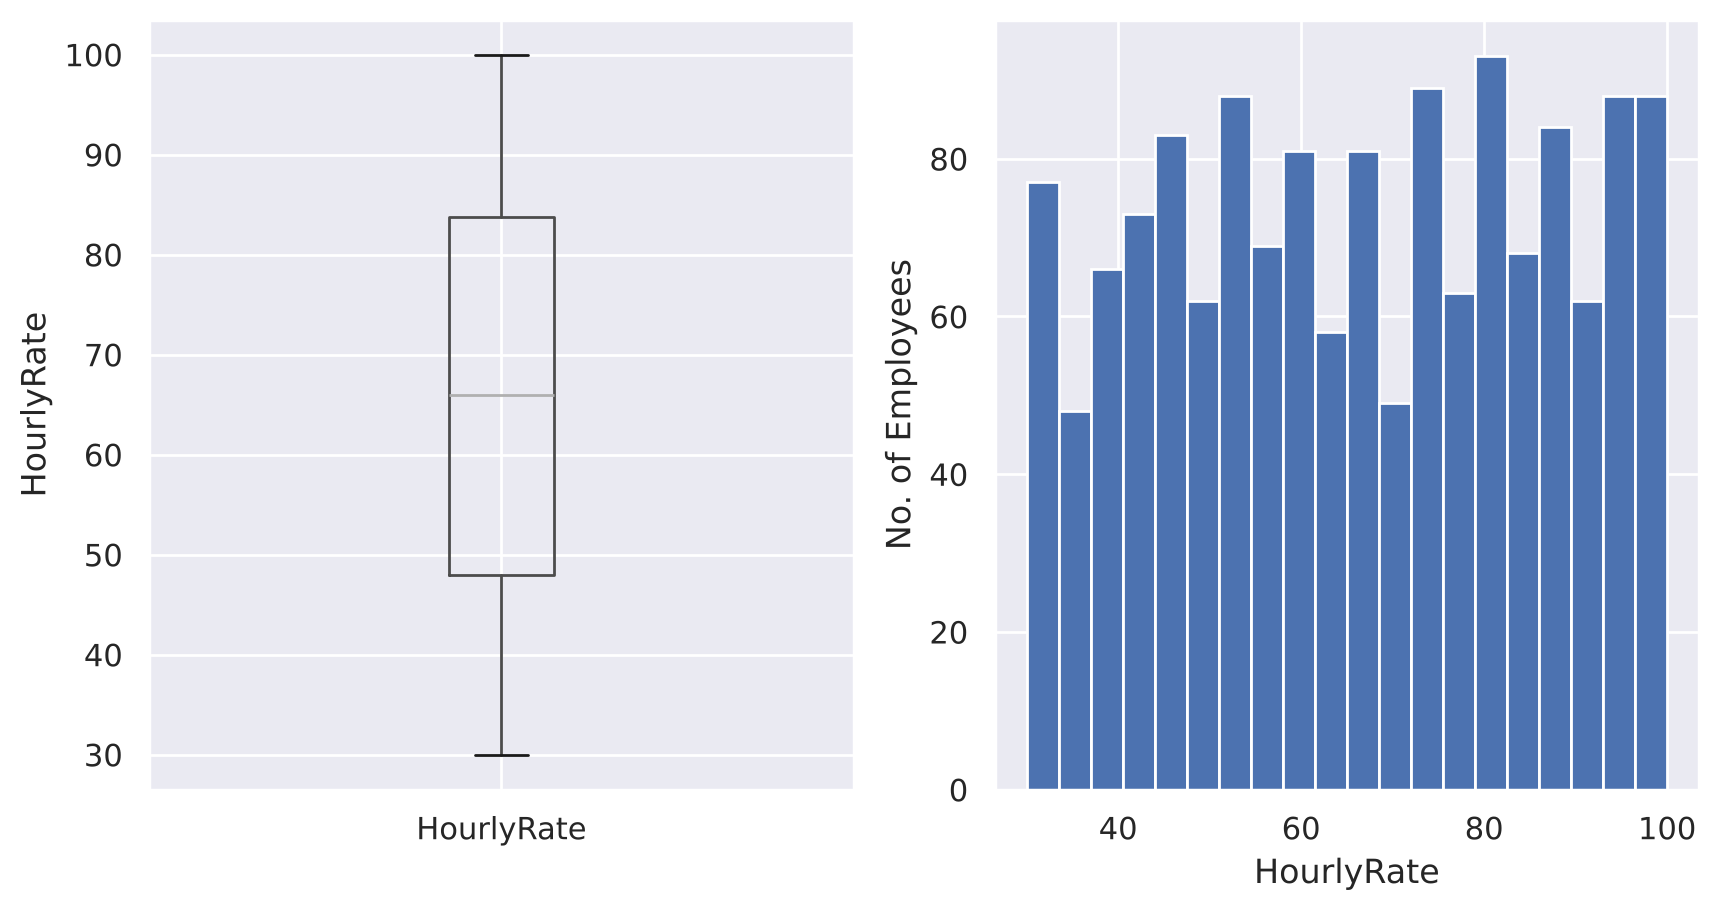

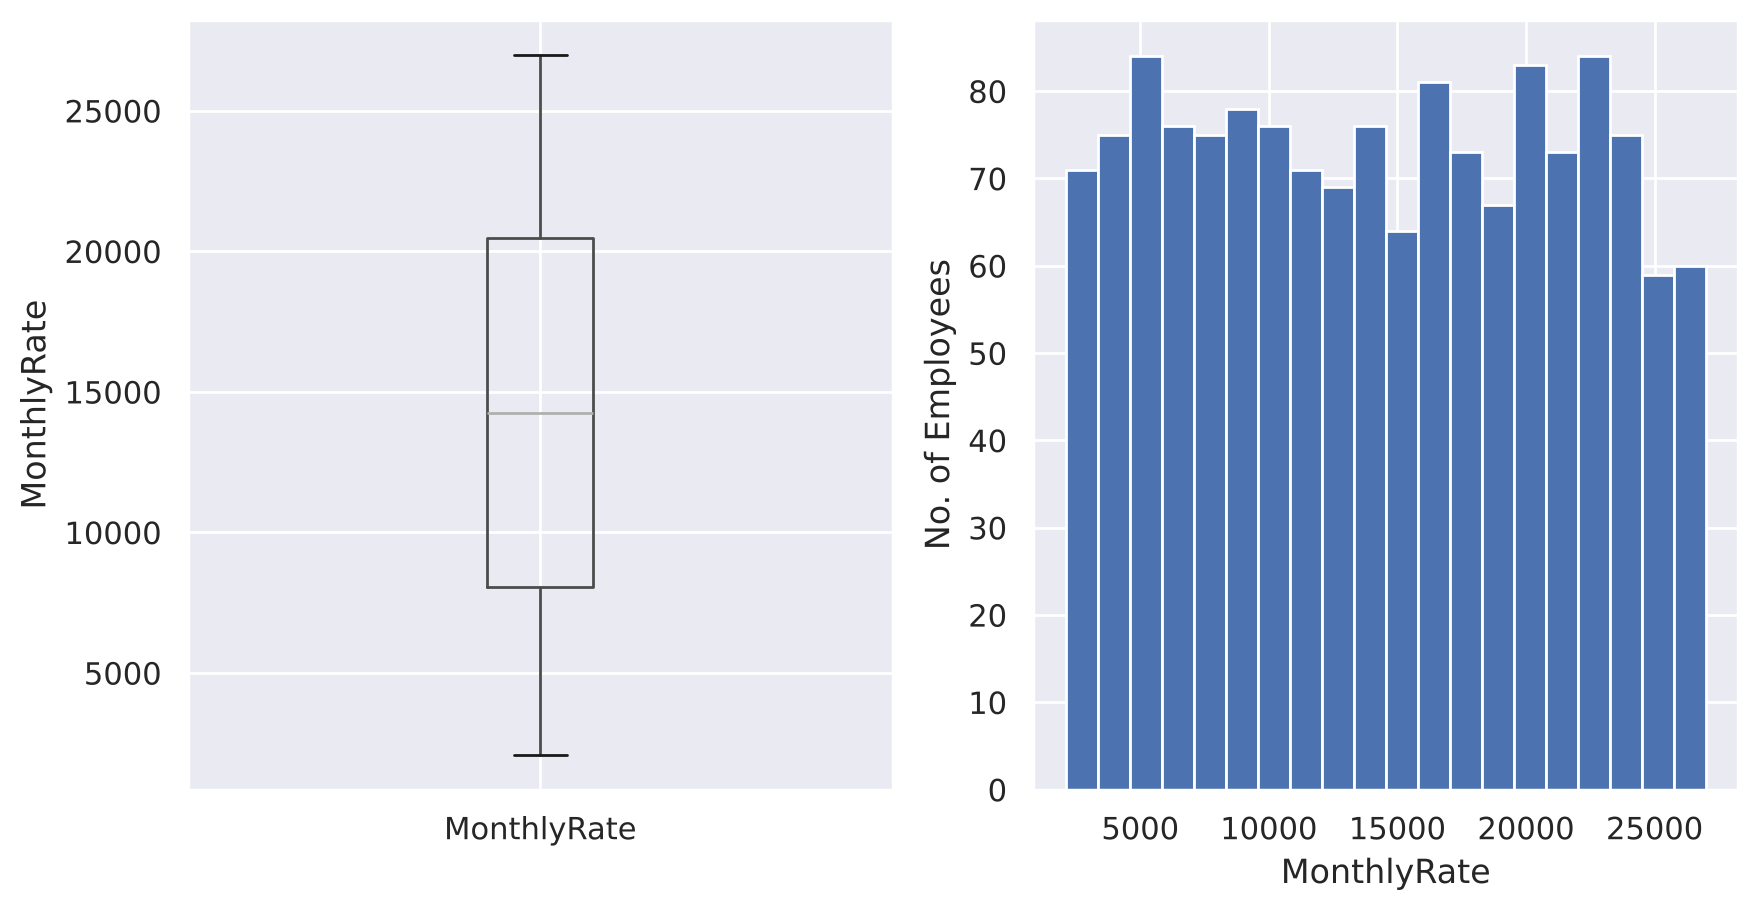

In [18]:
#Draw Box plot and histogram for the continious variables
for var in continious:
    #boxplot
    plt.figure(figsize = (10,5))
    plt.subplot(1,2,1)
    fig = attrition.boxplot(column = var)
    fig.set_ylabel(var)
    
    #histogram
    plt.subplot(1,2,2)
    fig = attrition[var].hist(bins = 20)
    fig.set_ylabel('No. of Employees')
    fig.set_xlabel(var)
    
    plt.show()

In [19]:
attrition['TotalWorkingYears'].describe()

count    1470.000000
mean       11.279592
std         7.780782
min         0.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        40.000000
Name: TotalWorkingYears, dtype: float64

In [20]:
categorical.columns

Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'Over18', 'OverTime'],
      dtype='str')

In [21]:
categorical.head()

,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
0,Travel_Rarely,Sales,Life Sciences,Female,Sales Executive,Single,Y,Yes
1,Travel_Frequently,Research & Development,Life Sciences,Male,Research Scientist,Married,Y,No
2,Travel_Rarely,Research & Development,Other,Male,Laboratory Technician,Single,Y,Yes
3,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Married,Y,Yes
4,Travel_Rarely,Research & Development,Medical,Male,Laboratory Technician,Married,Y,No


In [22]:
attrition_cat = pd.get_dummies(categorical)

In [23]:
attrition_cat.head()

,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Human Resources,Department_Research & Development,Department_Sales,EducationField_Human Resources,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,...,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Over18_Y,OverTime_No,OverTime_Yes
0,False,False,True,False,False,True,False,True,False,False,...,False,False,True,False,False,False,True,True,False,True
1,False,True,False,False,True,False,False,True,False,False,...,False,True,False,False,False,True,False,True,True,False
2,False,False,True,False,True,False,False,False,False,False,...,False,False,False,False,False,False,True,True,False,True
3,False,True,False,False,True,False,False,True,False,False,...,False,True,False,False,False,True,False,True,False,True
4,False,False,True,False,True,False,False,False,False,True,...,False,False,False,False,False,True,False,True,True,False


In [24]:
numerical.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,1102,1,2,1,1,2,94,3,...,1,80,0,8,0,1,6,4,0,5
1,49,0,279,8,1,1,2,3,61,2,...,4,80,1,10,3,3,10,7,1,7
2,37,1,1373,2,2,1,4,4,92,2,...,2,80,0,7,3,3,0,0,0,0
3,33,0,1392,3,4,1,5,4,56,3,...,3,80,0,8,3,3,8,7,3,0
4,27,0,591,2,1,1,7,1,40,3,...,4,80,1,6,3,3,2,2,2,2


In [25]:
attrition_final = pd.concat([numerical,attrition_cat], axis=1)

In [26]:
attrition_final.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,...,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Over18_Y,OverTime_No,OverTime_Yes
0,41,1,1102,1,2,1,1,2,94,3,...,False,False,True,False,False,False,True,True,False,True
1,49,0,279,8,1,1,2,3,61,2,...,False,True,False,False,False,True,False,True,True,False
2,37,1,1373,2,2,1,4,4,92,2,...,False,False,False,False,False,False,True,True,False,True
3,33,0,1392,3,4,1,5,4,56,3,...,False,True,False,False,False,True,False,True,False,True
4,27,0,591,2,1,1,7,1,40,3,...,False,False,False,False,False,True,False,True,True,False


In [27]:
attrition_final = attrition_final.drop('Attrition', axis = 1)
target = attrition['Attrition']

In [28]:
#Import the packages for the Models
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix




In [29]:
#Split the data into Test and Train
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(attrition_final ,target, test_size = 0.2, random_state = 0)


#Logistic Linear Regression



Classification report:
               precision    recall  f1-score   support

           0       0.85      0.98      0.91       245
           1       0.60      0.12      0.20        49

    accuracy                           0.84       294
   macro avg       0.72      0.55      0.56       294
weighted avg       0.81      0.84      0.79       294

Confusion Matrix:
 [[241   4]
 [ 43   6]]


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


<Axes: >

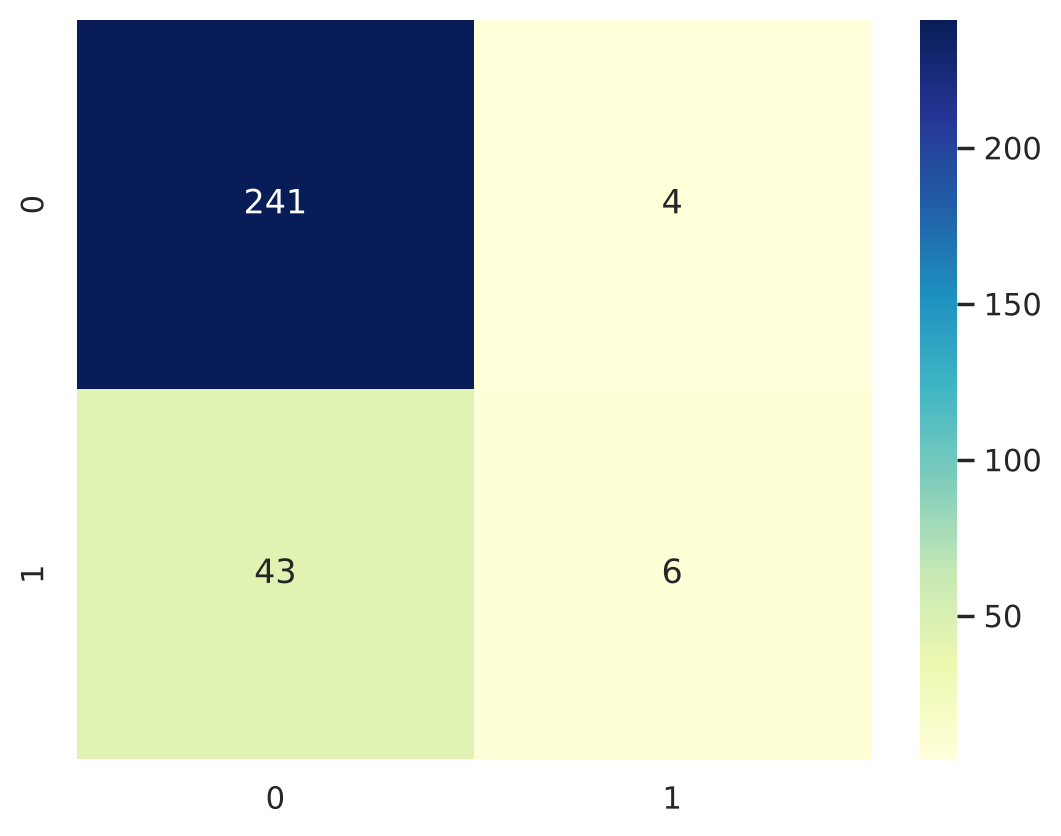

In [30]:
# Instantiate a Logistic Regression model
logreg_model = LogisticRegression(max_iter=1000)

# Fit the model to the training data
logreg_model.fit(x_train, y_train)

# Make predictions on the test data
y_pred1 = logreg_model.predict(x_test)

# Calculate classification report
report1 = classification_report(y_test, y_pred1)
print("Classification report:\n", report1)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred1)


# Print confusion matrix
print("Confusion Matrix:\n", cm)
sns.heatmap(confusion_matrix(y_test, y_pred1), annot=True, cmap="YlGnBu", fmt='g')



#Random Forest Model

Classification report:
               precision    recall  f1-score   support

           0       0.86      0.99      0.92       245
           1       0.82      0.18      0.30        49

    accuracy                           0.86       294
   macro avg       0.84      0.59      0.61       294
weighted avg       0.85      0.86      0.82       294

Confusion Matrix:
 [[243   2]
 [ 40   9]]


<Axes: >

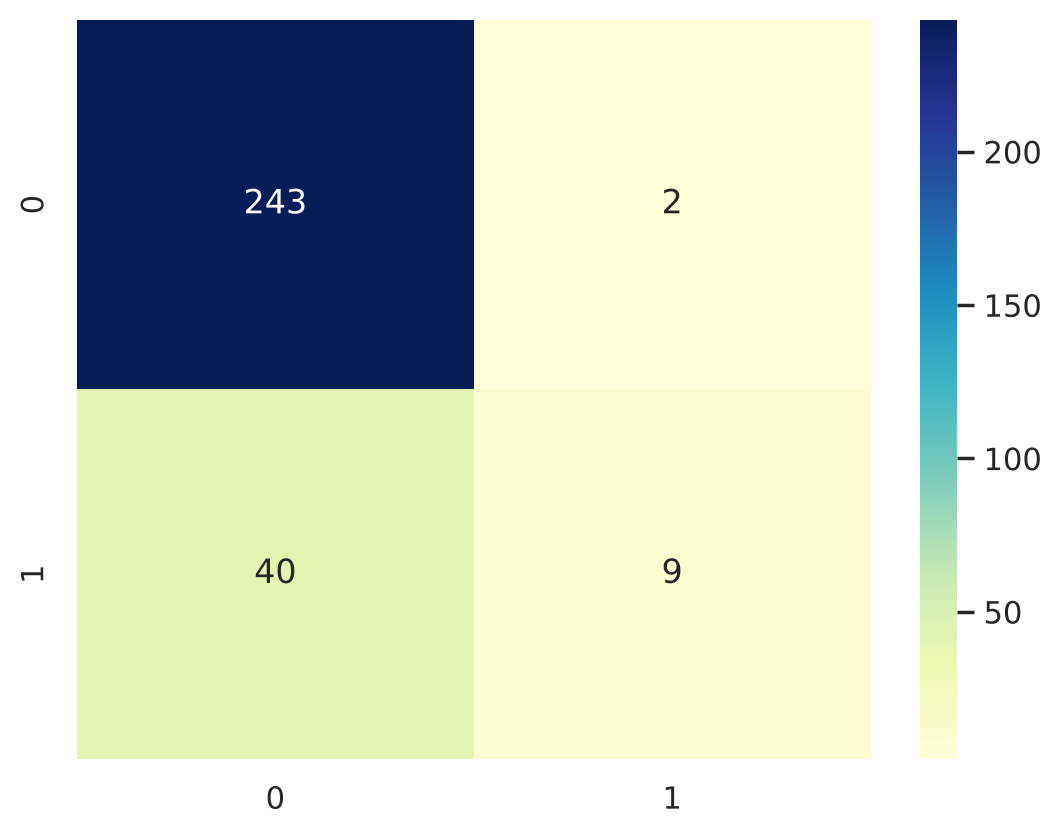

In [31]:

# Fit the Random Forest model
model = RandomForestClassifier()
model.fit(x_train, y_train)

# Make predictions on the test set
y_pred2 = model.predict(x_test)

# Calculate classification report
report2 = classification_report(y_test, y_pred2)


# Print the performance metrics

print("Classification report:\n", report2)

# Generate confusion matrix
cm2 = confusion_matrix(y_test, y_pred2)

# Print confusion matrix
print("Confusion Matrix:\n", cm2)
sns.heatmap(confusion_matrix(y_test, y_pred2), annot=True, cmap="YlGnBu", fmt='g')



#Decision Tree

Classification report:
               precision    recall  f1-score   support

           0       0.87      0.86      0.87       245
           1       0.35      0.37      0.36        49

    accuracy                           0.78       294
   macro avg       0.61      0.61      0.61       294
weighted avg       0.78      0.78      0.78       294

Confusion matrix:
 [[211  34]
 [ 31  18]]


<Axes: >

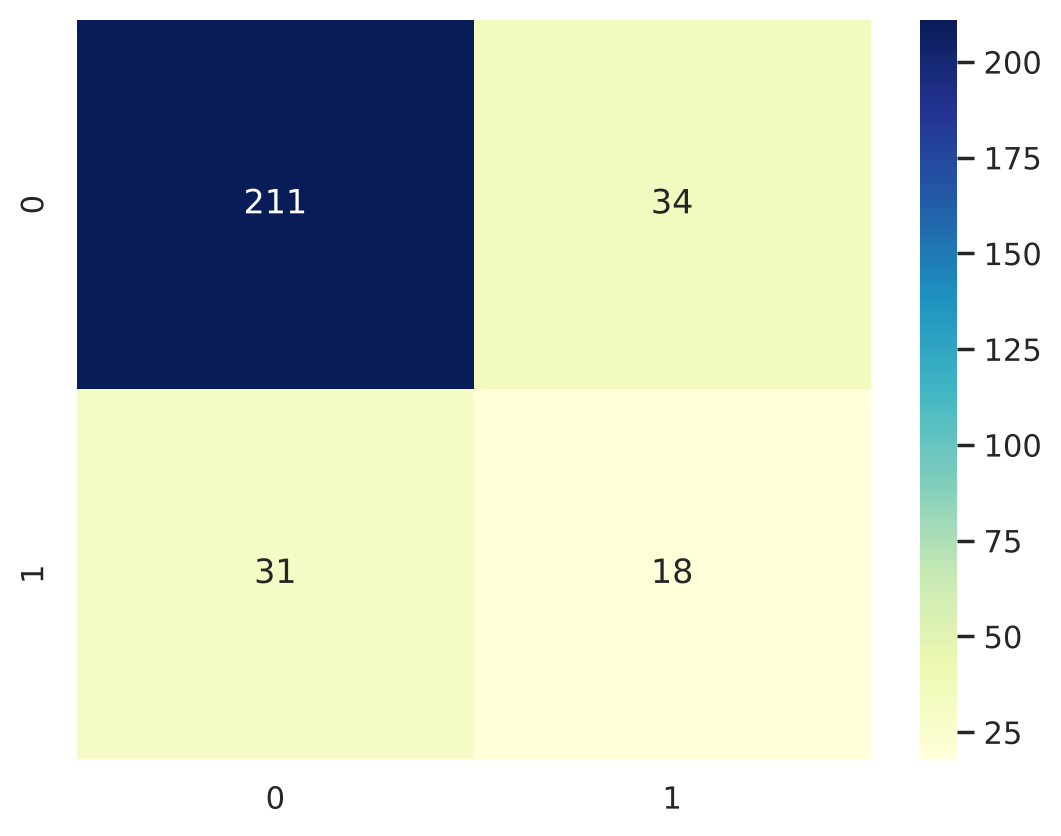

In [32]:
# Define the Decision Tree model
dt_model = DecisionTreeClassifier()

# Fit the model on the training data
dt_model.fit(x_train, y_train)

# Make predictions on the test data
y_pred3 = dt_model.predict(x_test)

# Calculate classification report
report3 = classification_report(y_test, y_pred3)

# Print the classification report
print("Classification report:\n", report3)

# Print the confusion matrix
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred3))
sns.heatmap(confusion_matrix(y_test, y_pred3), annot=True, cmap="YlGnBu", fmt='g')

#Comparison between the 3 Models - 
- Logistic Regression
- Random Forest
- Decision Tree

In [33]:
# Calculate the accuracy, precision, recall, and F1-score for each model
accuracy1 = accuracy_score(y_test, y_pred1)
accuracy2 = accuracy_score(y_test, y_pred2)
accuracy3 = accuracy_score(y_test, y_pred3)

report1 = classification_report(y_test, y_pred1, output_dict=True)
report2 = classification_report(y_test, y_pred2, output_dict=True)
report3 = classification_report(y_test, y_pred3, output_dict=True)

df = pd.DataFrame({'Model': ['Logistic Regression', 'Random Forest', 'Decision Tree'],
                   'Accuracy': [accuracy1, accuracy2, accuracy3],
                   'Precision': [report1['weighted avg']['precision'], report2['weighted avg']['precision'], report3['weighted avg']['precision']],
                   'Recall': [report1['weighted avg']['recall'], report2['weighted avg']['recall'], report3['weighted avg']['recall']],
                   'F1-Score': [report1['weighted avg']['f1-score'], report2['weighted avg']['f1-score'], report3['weighted avg']['f1-score']]})



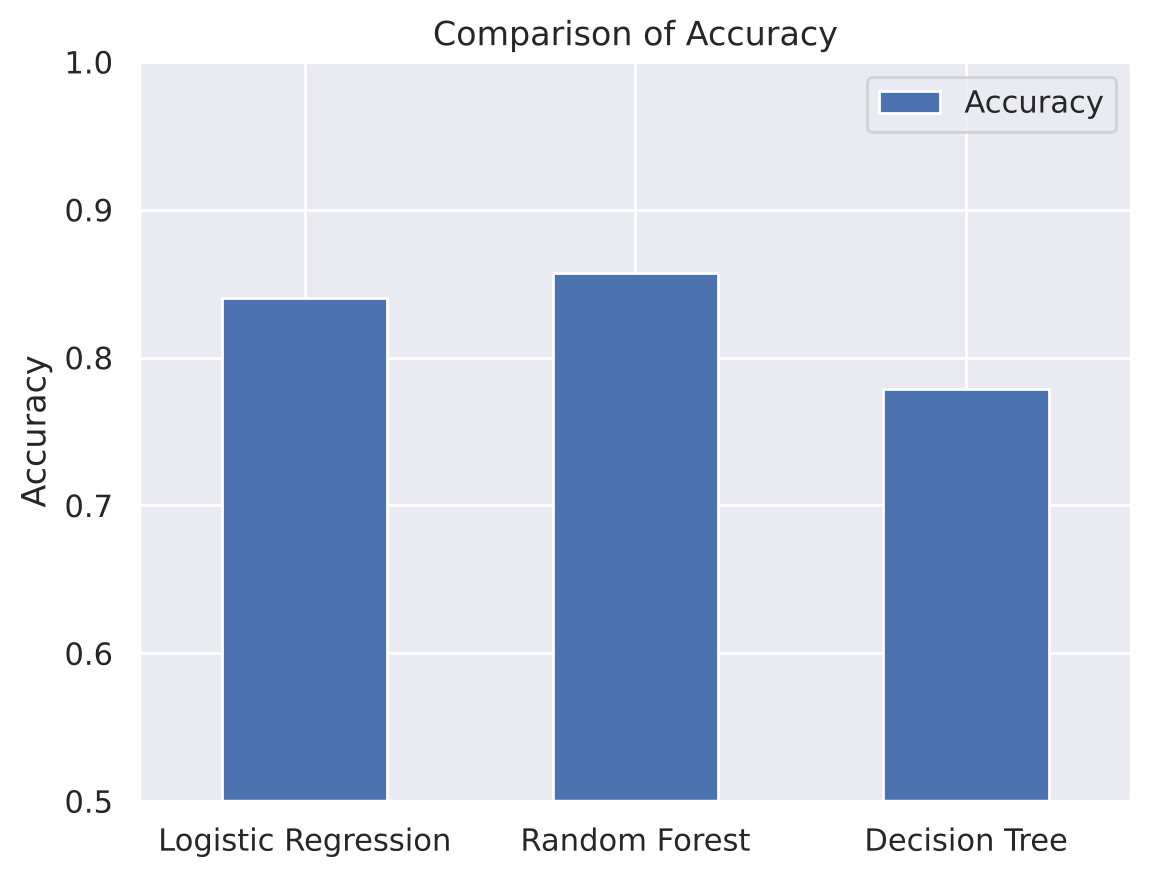

In [34]:
# Visualize the results using a bar plot
ax = df.plot(kind='bar', x='Model', y='Accuracy', rot=0)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel('')
ax.set_ylabel('Accuracy')
ax.set_title('Comparison of Accuracy')
plt.show()


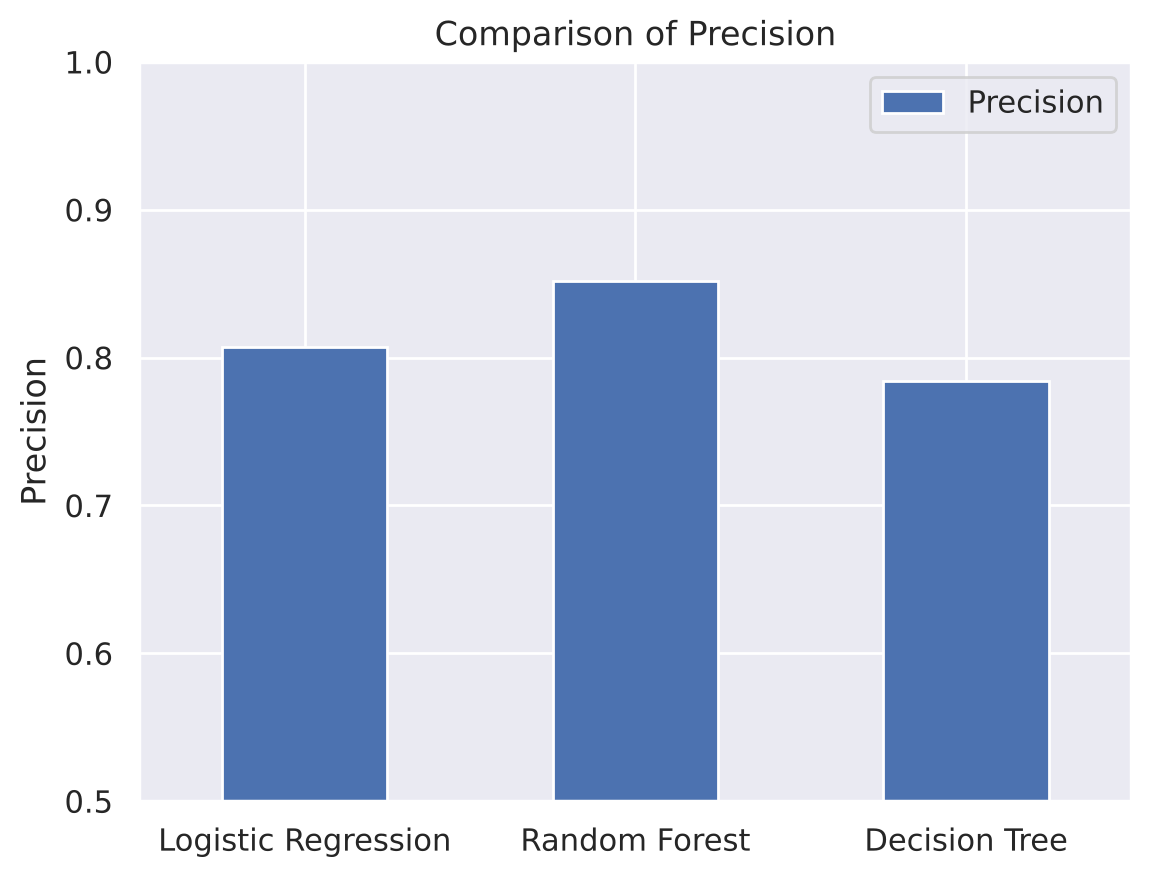

In [35]:
# Visualize the results using a bar plot
ax = df.plot(kind='bar', x='Model', y='Precision', rot=0)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel('')
ax.set_ylabel('Precision')
ax.set_title('Comparison of Precision')
plt.show()


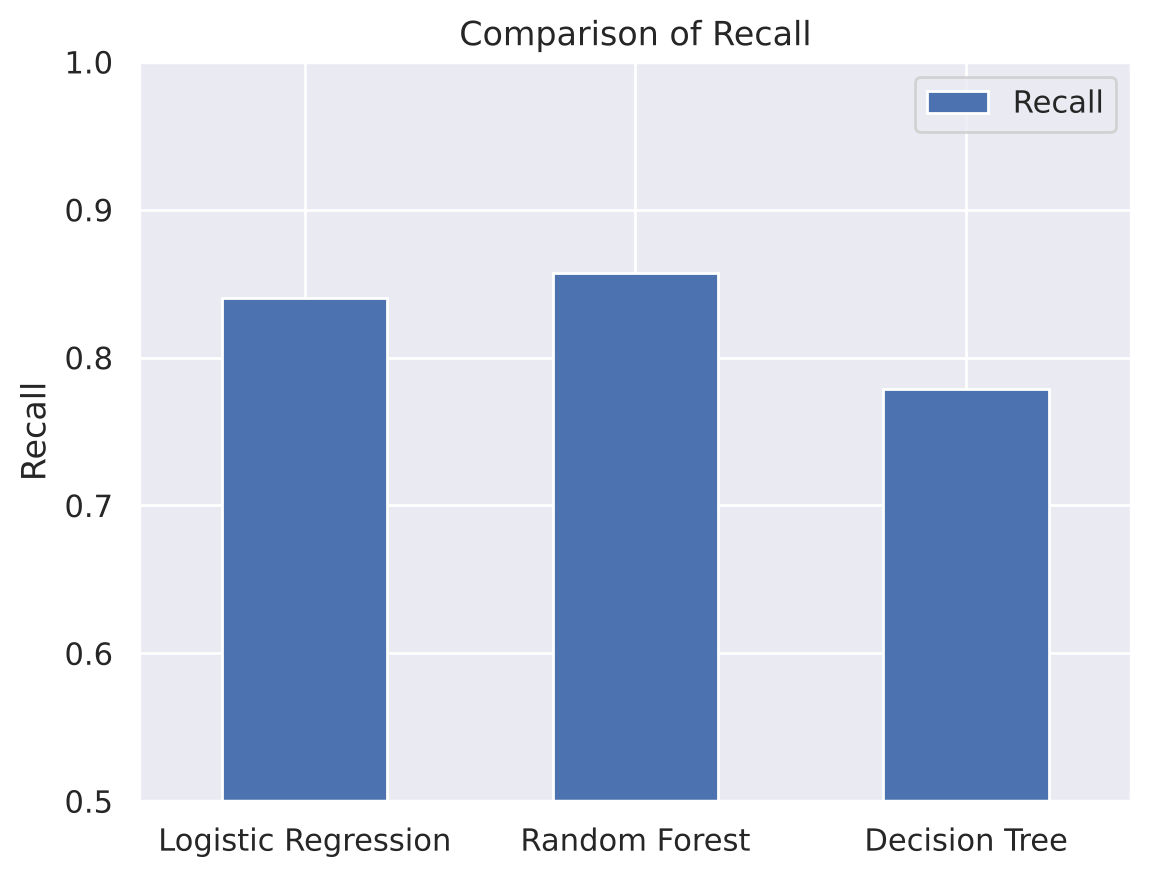

In [36]:
# Visualize the results using a bar plot
ax = df.plot(kind='bar', x='Model', y='Recall', rot=0)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel('')
ax.set_ylabel('Recall')
ax.set_title('Comparison of Recall')
plt.show()


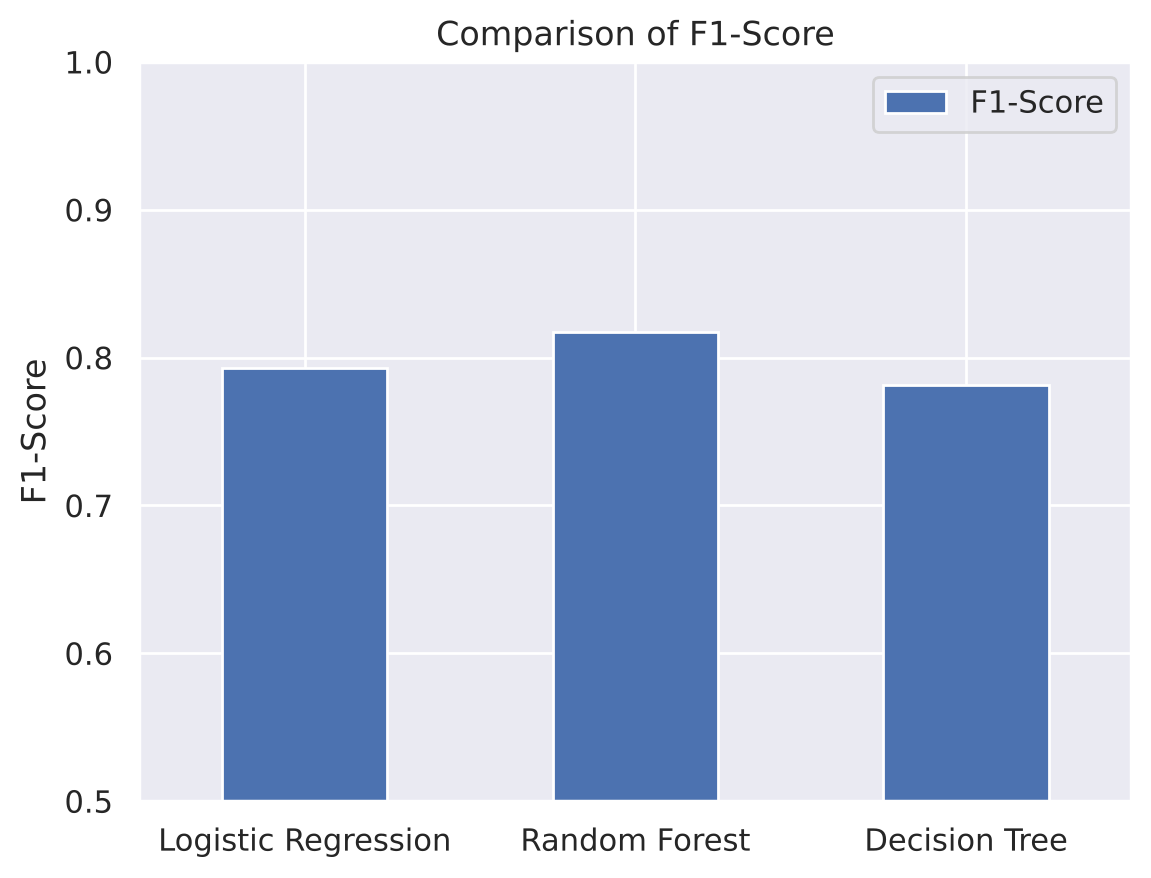

In [37]:
# Visualize the results using a bar plot
ax = df.plot(kind='bar', x='Model', y='F1-Score', rot=0)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel('')
ax.set_ylabel('F1-Score')
ax.set_title('Comparison of F1-Score')
plt.show()


Grid Search

In [38]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# create a Random Forest classifier object
rf = RandomForestClassifier(random_state=42)

# create a GridSearchCV object
grid_search = GridSearchCV(rf, param_grid=param_grid, cv=5, n_jobs=-1)

# fit the GridSearchCV object to the data
grid_search.fit(x_train, y_train)

# print the best hyperparameters
print('Best hyperparameters:', grid_search.best_params_)

Best hyperparameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


# Improved models: stratified split, class weighting and ROC-AUC

Only about 16% of employees leave, so a model that always predicts "stays" is right about 84% of the time and finds no leavers at all. Accuracy hides that, so this section judges the models on what matters here: how many leavers they find (recall), how many of their warnings are right (precision) and how well they rank people by risk (ROC-AUC).

Changes against the baseline above: a **stratified** split (train and test keep the same leaver share), **class weighting** so leavers count for more, and a **scaled** logistic regression.

In [39]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

X_tr, X_te, y_tr, y_te = train_test_split(attrition_final, target, test_size=0.2, random_state=0, stratify=target)
print("Leavers in train / test: %.1f%% / %.1f%%" % (100*y_tr.mean(), 100*y_te.mean()))
print("Always-predict-stays accuracy on test: %.3f" % (1 - y_te.mean()))

models = {
    "Logistic Regression (baseline)": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced, scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest (baseline)": RandomForestClassifier(n_estimators=300, random_state=42),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=3, random_state=42),
    "Decision Tree (balanced, depth 5)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
}
rows = []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    proba = m.predict_proba(X_te)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": (pred == y_te).mean(),
                 "Leaver precision": precision_score(y_te, pred, zero_division=0),
                 "Leaver recall": recall_score(y_te, pred),
                 "Leaver F1": f1_score(y_te, pred),
                 "ROC-AUC": roc_auc_score(y_te, proba)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results

Leavers in train / test: 16.2% / 16.0%
Always-predict-stays accuracy on test: 0.840


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy,Leaver precision,Leaver recall,Leaver F1,ROC-AUC
Model,,,,,
Logistic Regression (baseline),0.857,0.609,0.298,0.400,0.761
"Logistic Regression (balanced, scaled)",0.755,0.346,0.596,0.438,0.793
Random Forest (baseline),0.850,0.800,0.085,0.154,0.778
Random Forest (balanced),0.854,0.625,0.213,0.317,0.795
"Decision Tree (balanced, depth 5)",0.786,0.352,0.404,0.376,0.597


In [40]:
# Cross-validated ROC-AUC (5 stratified folds) so the ranking does not hinge on one split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for name, m in models.items():
    s = cross_val_score(m, attrition_final, target, cv=cv, scoring="roc_auc")
    print("%-42s ROC-AUC %.3f (+/- %.3f)" % (name, s.mean(), s.std()))

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression (baseline)             ROC-AUC 0.789 (+/- 0.020)
Logistic Regression (balanced, scaled)     ROC-AUC 0.826 (+/- 0.018)


Random Forest (baseline)                   ROC-AUC 0.804 (+/- 0.037)


Random Forest (balanced)                   ROC-AUC 0.805 (+/- 0.030)
Decision Tree (balanced, depth 5)          ROC-AUC 0.703 (+/- 0.043)


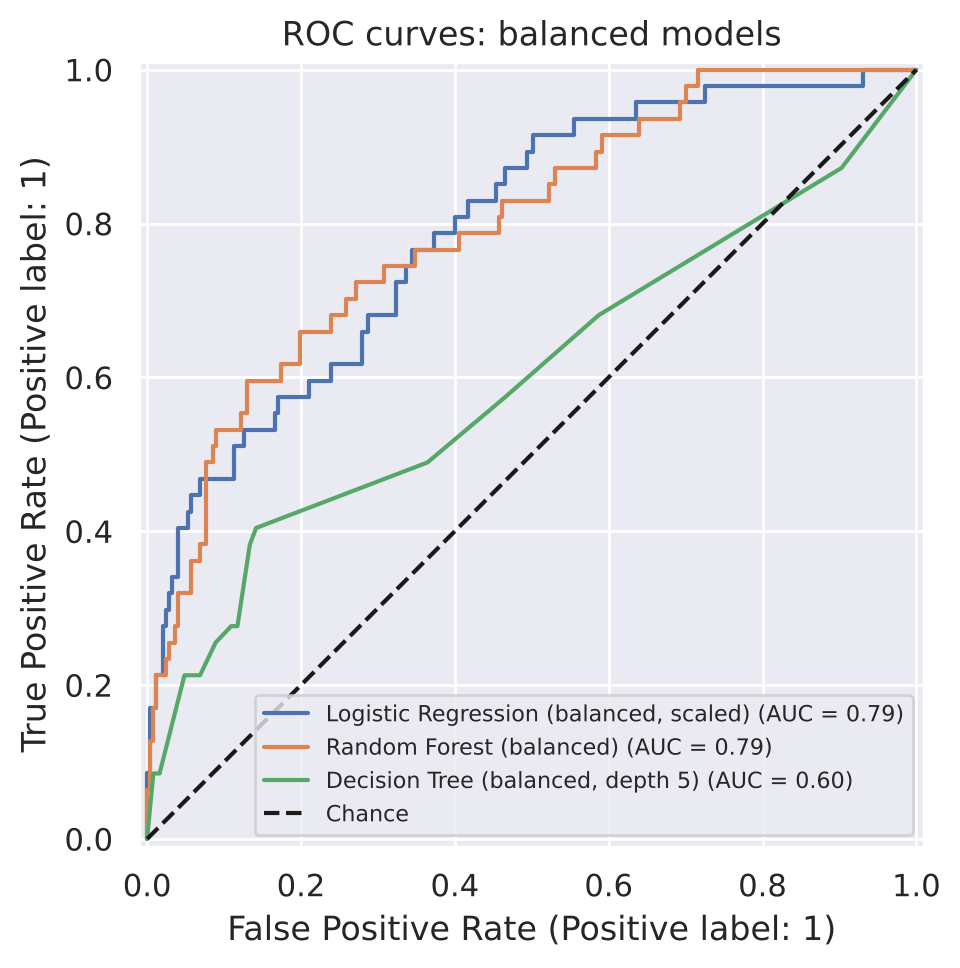

In [41]:
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["Logistic Regression (balanced, scaled)", "Random Forest (balanced)", "Decision Tree (balanced, depth 5)"]:
    RocCurveDisplay.from_estimator(models[name], X_te, y_te, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curves: balanced models")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("images/roc-curves.png", dpi=150); plt.show()